<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-06/beta-vae.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Disentangled representations with a β-VAE

*Deep Learning for Scientific Discovery, Jagiellonian University. Author: Marcin Płodzień.*

An autoencoder compresses an image $\mathbf x$ into a few numbers $z_1,\dots,z_d$, collected in the latent vector $\mathbf z$, and a decoder maps them back to an image. As a compressor it works, but it cannot generate: the codes of the training images occupy some irregular region of $\mathbb R^d$ whose shape nobody knows, so there is no rule for drawing a new $\mathbf z$ that decodes to a plausible image. The variational autoencoder (VAE) fixes the distribution of the codes in advance, the standard Gaussian prior
$$p(\mathbf z)=\mathcal N(0,I), \tag{1}$$
and trains an encoder $q_\phi(\mathbf z\,|\,\mathbf x)$ and a decoder $p_\theta(\mathbf x\,|\,\mathbf z)$ together so that the codes of the data fill this Gaussian and every $\mathbf z$ drawn from it decodes to something that looks like data.

Once the latent space is a known, continuous space, its coordinates become features: moving one coordinate $z_k$ changes the decoded image, and one can ask what it changes. Nothing in the VAE objective asks that the answer be simple. A digit's slant may be spread over five coordinates, each of which also changes its width and thickness. The goal of disentanglement is a latent space in which each coordinate controls one distinct feature and leaves the others alone. In science this is the difference between a compression and an explanation: a coordinate that tracks one physical cause can be read, tested and reused.

The simplest model that pushes a VAE in that direction is the β-VAE of Higgins et al. (2017). It is trained on dSprites, a data set of images rendered from five known factors, so that the learnt coordinates can be compared with the truth: the Kullback–Leibler (KL) divergence per coordinate, latent traversals, the mutual information between coordinates and factors, the cost in reconstruction, and what sampling from the trained models produces. A short section on handwritten digits closes the loop with the VAE of the lecture.

The notation follows the lecture: encoder $q_\phi(\mathbf z\,|\,\mathbf x)$, decoder $p_\theta(\mathbf x\,|\,\mathbf z)$, prior $p(\mathbf z)$ of equation (1), $d$ latent coordinates. Equations are numbered and referred to as equation (n). Everything runs on the central processing unit (CPU); trained weights are stored in `results/` and reloaded on later runs.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""                          # CPU only
import json, time, gzip, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, FancyArrowPatch
import torch, torch.nn as nn, torch.nn.functional as F
torch.set_num_threads(4)
import os
OUT = "figures"; os.makedirs(OUT, exist_ok=True); os.makedirs(OUT, exist_ok=True)       # figures of the slides
RES = "results"; os.makedirs(RES, exist_ok=True)                 # weights and numbers
DATA = "data"; os.makedirs(DATA, exist_ok=True)
blue, orange, navy, grey = "#005CA7", "#EB6709", "#0A2F5C", "#9A9A9A"
plt.rcParams.update({"font.size": 15, "axes.titlesize": 16, "axes.labelsize": 15, "xtick.labelsize": 13, "ytick.labelsize": 13,
                     "legend.fontsize": 13, "figure.titlesize": 17, "savefig.facecolor": "white"})
nums = {}                                                         # numbers quoted on the slides
def clean(ax):
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
def seed(k):
    torch.manual_seed(k); np.random.seed(k); return np.random.default_rng(k)
T0 = time.time()

## Disentanglement

Suppose the images in a data set are produced by a simulator with a handful of independent inputs $v_1,\dots,v_K$, the generative factors: the position of an object, its size, its orientation, its shape. A representation $\mathbf z$ is called disentangled when each coordinate $z_k$ responds to one factor and is insensitive to the others. Changing $z_k$ then changes one property of the decoded image and leaves the rest of the image unchanged; conversely, moving the object in the image changes one coordinate only. An entangled representation can carry exactly the same information, mixed by some rotation of the latent space, so that every coordinate depends on several factors at once.

The conditional VAE of the lecture solved a related but easier problem. There the factor of interest, the digit class or the blood-cell type, was supplied as a label $\mathbf c$ to both networks, $q_\phi(\mathbf z\,|\,\mathbf x,\mathbf c)$ and $p_\theta(\mathbf x\,|\,\mathbf z,\mathbf c)$, and the latent space kept only the remaining style. Here no labels are given. The factors must be discovered from the images alone, and the only leverage we have is the shape of the objective.

## The β-VAE objective

For one image $\mathbf x$ the VAE minimises minus the evidence lower bound (ELBO),
$$-\mathrm{ELBO}(\mathbf x)=\mathbb E_{q_\phi(\mathbf z|\mathbf x)}\big[-\log p_\theta(\mathbf x\,|\,\mathbf z)\big]+\mathrm{KL}\big(q_\phi(\mathbf z\,|\,\mathbf x)\,\|\,p(\mathbf z)\big). \tag{2}$$
Higgins et al. (2017) start instead from a constrained problem: make the reconstruction as good as possible while keeping the KL divergence of the encoder from the prior below a budget $\varepsilon$,
$$\max_{\phi,\theta}\ \mathbb E_{\mathbf x}\,\mathbb E_{q_\phi(\mathbf z|\mathbf x)}\big[\log p_\theta(\mathbf x\,|\,\mathbf z)\big]\quad\text{subject to}\quad \mathrm{KL}\big(q_\phi(\mathbf z\,|\,\mathbf x)\,\|\,p(\mathbf z)\big)<\varepsilon . \tag{3}$$
The Lagrangian of this problem, with a non-negative Karush–Kuhn–Tucker multiplier $\beta$, gives after dropping the constant $\beta\varepsilon$ the β-VAE loss
$$\mathcal L_\beta(\mathbf x)=\mathbb E_{q_\phi(\mathbf z|\mathbf x)}\big[-\log p_\theta(\mathbf x\,|\,\mathbf z)\big]+\beta\,\mathrm{KL}\big(q_\phi(\mathbf z\,|\,\mathbf x)\,\|\,p(\mathbf z)\big). \tag{4}$$
With β equal to 1, equation (4) is equation (2), the VAE loss of Kingma and Welling (2014). For β larger than 1 it is no longer a bound on the log-likelihood; it is a different trade-off between the two terms.

The encoder outputs a diagonal Gaussian,
$$q_\phi(\mathbf z\,|\,\mathbf x)=\mathcal N\big(\boldsymbol\mu(\mathbf x),\operatorname{diag}\boldsymbol\sigma^2(\mathbf x)\big), \tag{5}$$
and the prior (1) factorises too, into $d$ independent standard normal coordinates. The KL divergence between two products of independent factors is the sum of the KL divergences of the factors, so the penalty splits into one term per coordinate,
$$\mathrm{KL}\big(q_\phi(\mathbf z\,|\,\mathbf x)\,\|\,p(\mathbf z)\big)=\sum_{k=1}^{d}\mathrm{KL}_k, \tag{6}$$
$$\mathrm{KL}_k=\tfrac12\big(\mu_k^2+\sigma_k^2-\ln\sigma_k^2-1\big). \tag{7}$$
$\mathrm{KL}_k$ vanishes only for zero mean and unit width, that is, when $z_k$ is pure prior noise whatever the input: such a coordinate carries no information about $\mathbf x$. Averaged over the data, $\mathrm{KL}_k$ is an upper bound on the information, in nats (one nat is about 1.44 bits), that the noisy channel $z_k$ transmits about the image (Burgess et al., 2018). The loss (4) therefore charges $\beta$ units per nat sent through each coordinate.

This price explains the pressure towards disentanglement. When information is expensive, the model sends only what reduces the reconstruction error most per nat, and it sends it through as few coordinates as possible; the remaining coordinates collapse onto the prior. Burgess et al. describe the consequence: under a tight bottleneck a β-VAE on dSprites first encodes position, because a sprite misplaced by a few pixels destroys the pixel-wise likelihood, and as the budget grows it adds scale, then other factors, each in a coordinate of its own. Since the prior is isotropic and factorised, independent factors placed on separate axes are also the cheapest arrangement for the KL term. The price is paid in reconstruction: information that does not fit through the bottleneck is lost, and the decoded images become blurrier.

In [2]:
# KL_k from equation (7), checked against torch.distributions for a few (mu, sigma)
from torch.distributions import Normal, kl_divergence
mu_ = torch.tensor([0.0, 0.0, 1.0, 2.0, 0.0]); sd_ = torch.tensor([1.0, 0.5, 1.0, 0.1, 0.05])
kl_formula = 0.5 * (mu_ ** 2 + sd_ ** 2 - torch.log(sd_ ** 2) - 1)
kl_torch = kl_divergence(Normal(mu_, sd_), Normal(0.0, 1.0))
for m, s, a, b in zip(mu_, sd_, kl_formula, kl_torch):
    print(f"mu = {m:4.1f}, sigma = {s:4.2f}:  KL_k = {a:.4f} nats (formula) = {b:.4f} (torch)")

mu =  0.0, sigma = 1.00:  KL_k = 0.0000 nats (formula) = 0.0000 (torch)
mu =  0.0, sigma = 0.50:  KL_k = 0.3181 nats (formula) = 0.3181 (torch)
mu =  1.0, sigma = 1.00:  KL_k = 0.5000 nats (formula) = 0.5000 (torch)
mu =  2.0, sigma = 0.10:  KL_k = 3.8076 nats (formula) = 3.8076 (torch)
mu =  0.0, sigma = 0.05:  KL_k = 2.4970 nats (formula) = 2.4970 (torch)


A coordinate that only shifts its mean by one prior standard deviation costs half a nat. Narrowing the posterior is what becomes expensive: a width of 0.05 costs about 2.5 nats even at zero mean. A sharp, informative coordinate is costly, a vague one is cheap, and the multiplier $\beta$ decides how many sharp coordinates the model can afford.

## The dSprites data

The data set dSprites, *Disentanglement testing Sprites* (Matthey et al., 2017), was built at DeepMind as a test bench for disentanglement. Each sample $\mathbf x_i$ is a binary image of $64\times64$ pixels; every pixel is either 1, a white pixel of the sprite, or 0, the black background. The images are not photographs: they were rendered by a program from five numbers, the generative factors,

- shape: square, ellipse or heart (3 values);
- scale: the size of the sprite, 6 values from 0.5 to 1;
- orientation: rotation angle, 40 values equally spaced from 0 to $2\pi$;
- position $x$: horizontal position, 32 values from 0 to 1;
- position $y$: vertical position, 32 values from 0 to 1.

(A sixth factor, colour, has a single value, white.) Every combination of the factors appears exactly once, which gives 737,280 images ($3\cdot6\cdot40\cdot32\cdot32$), stored in a fixed order from which the factors of any image can be read off; no noise was added. The factors are therefore independent by construction and known for every image. The data are distributed with a description of the factors at [github.com/deepmind/dsprites-dataset](https://github.com/deepmind/dsprites-dataset) under the Apache 2.0 licence.

The archive (about 19 MB, 3 GB once unpacked) is downloaded once into `data/dsprites/`. To keep training within reach of a CPU we draw 110,000 images at random, 100,000 for training and 10,000 for testing, and reduce them to $32\times32$ by averaging $2\times2$ blocks and thresholding at one half, which keeps them binary. The subset, together with a few rows of full-resolution images, is cached, so the 3 GB array is unpacked only on the first run.

In [3]:
DS = os.path.join(DATA, "dsprites"); os.makedirs(DS, exist_ok=True)
NPZ = os.path.join(DS, "dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz")
SUB = os.path.join(DS, "dsprites_subset_32x32.npz")
URLS = ["https://github.com/google-deepmind/dsprites-dataset/raw/master/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz",
        "https://github.com/deepmind/dsprites-dataset/raw/master/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz",
        "https://raw.githubusercontent.com/google-deepmind/dsprites-dataset/master/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz"]
FACTORS = ["shape", "scale", "orientation", "position x", "position y"]
SHAPES = ["square", "ellipse", "heart"]
N_TRAIN, N_TEST = 100_000, 10_000
SIZES = np.array([1, 3, 6, 40, 32, 32])                            # colour, shape, scale, orientation, x, y
BASES = np.concatenate([SIZES[::-1].cumprod()[::-1][1:], [1]])    # image index = sum_j class_j * BASES_j
ROWS = {"shape": [0, 1, 2], "scale": list(range(6)), "orientation": [0, 3, 6, 10, 13, 16, 20, 26],
        "position x": [0, 4, 9, 13, 18, 22, 27, 31], "position y": [0, 4, 9, 13, 18, 22, 27, 31]}
BASE = [0, 2, 5, 0, 16, 16]                                       # heart, largest scale, angle 0, centre

if not os.path.exists(SUB):
    if not os.path.exists(NPZ):
        for u in URLS:
            try:
                urllib.request.urlretrieve(u, NPZ); break
            except Exception as e:
                print("download failed:", u, e)
    raw = np.load(NPZ, allow_pickle=True, encoding="latin1")
    imgs, classes, values = raw["imgs"], raw["latents_classes"], raw["latents_values"]
    print("full data set:", imgs.shape, imgs.dtype, " factor sizes:", raw["metadata"][()]["latents_sizes"])
    rng = seed(0)
    idx = rng.choice(len(imgs), N_TRAIN + N_TEST, replace=False)
    small = (imgs[idx].reshape(-1, 32, 2, 32, 2).mean((2, 4)) >= 0.5).astype(np.uint8)   # 2x2 average, threshold
    grid = {}                                                     # full-resolution rows, one factor varied per row
    for j, f in enumerate(FACTORS):
        ids = []
        for v in ROWS[f]:
            cl = list(BASE); cl[j + 1] = v; ids.append(int(np.dot(cl, BASES)))
        grid["g_" + f] = imgs[ids]; grid["gv_" + f] = values[ids, j + 1]
    sq = lambda o: int(np.dot([0, 0, 5, o, 16, 16], BASES))      # a large centred square at orientation index o
    sym = np.array([(imgs[sq(0)] != imgs[sq(o)]).mean() for o in range(40)])
    np.savez_compressed(SUB, x=small, c=classes[idx, 1:], v=values[idx, 1:], idx=idx, sym=sym,
                        angles=raw["metadata"][()]["latents_possible_values"]["orientation"], **grid)
    del raw, imgs, classes, values

sub = np.load(SUB)
X = torch.tensor(sub["x"], dtype=torch.float32).unsqueeze(1)      # (N, 1, 32, 32)
C, V = sub["c"], sub["v"]                                         # factor classes (integers) and values
Xtr, Xte, Cte, Vte = X[:N_TRAIN], X[N_TRAIN:], C[N_TRAIN:], V[N_TRAIN:]
print("training images:", tuple(Xtr.shape), "  test images:", tuple(Xte.shape))
print("values per factor:", {f: len(np.unique(C[:, i])) for i, f in enumerate(FACTORS)})
print(f"mean fraction of white pixels at 32 x 32: {Xtr.mean():.4f}")

training images: (100000, 1, 32, 32)   test images: (10000, 1, 32, 32)
values per factor: {'shape': 3, 'scale': 6, 'orientation': 40, 'position x': 32, 'position y': 32}
mean fraction of white pixels at 32 x 32: 0.0454


Starting from one image, a large heart at angle 0 in the centre of the canvas, each row changes one factor while the other four stay fixed. These are the original $64\times64$ images. A disentangled model should have one latent coordinate for each of these rows.

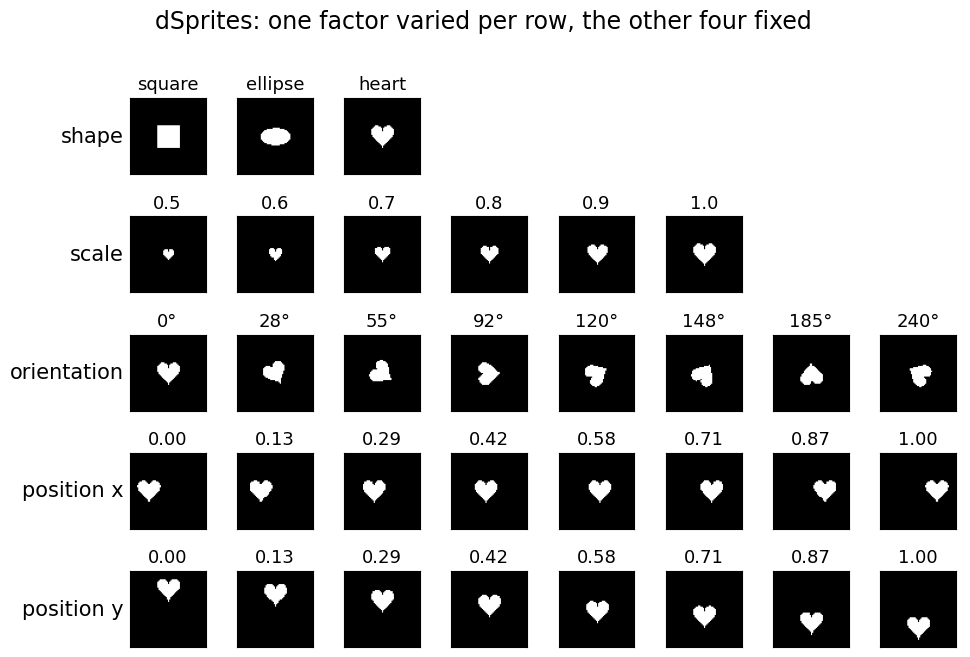

In [4]:
fig, axs = plt.subplots(5, 8, figsize=(10, 6.6))
fmt = {"shape": lambda v, i: SHAPES[i], "scale": lambda v, i: f"{v:.1f}", "orientation": lambda v, i: f"{np.degrees(v):.0f}°",
       "position x": lambda v, i: f"{v:.2f}", "position y": lambda v, i: f"{v:.2f}"}
for r, f in enumerate(FACTORS):
    g, gv = sub["g_" + f], sub["gv_" + f]
    for c in range(8):
        a = axs[r, c]; a.set_xticks([]); a.set_yticks([])
        if c < len(g):
            a.imshow(g[c], cmap="gray", vmin=0, vmax=1); a.set_title(fmt[f](gv[c], c), fontsize=13)
        else:
            a.axis("off")
        if c == 0: a.set_ylabel(f, rotation=0, ha="right", va="center", fontsize=15)
plt.suptitle("dSprites: one factor varied per row, the other four fixed", y=1.0)
plt.tight_layout(); plt.savefig(f"{OUT}/beta_vae_dsprites_examples.png", dpi=200, bbox_inches="tight"); plt.show()

factors (shape, scale, orientation, x, y): [ 0  1 23 25 24]  values: [1.    0.6   3.705 0.806 0.774]
[[0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 1 1 1 0 0 0]
 [0 0 0 0 1 1 1 1 1 0 0 0]
 [0 0 0 1 1 1 1 1 1 1 0 0]
 [0 0 0 1 1 1 1 1 1 1 0 0]
 [0 0 0 0 1 1 1 1 1 1 1 0]
 [0 0 0 0 0 1 1 1 1 0 0 0]
 [0 0 0 0 0 1 1 1 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0]]


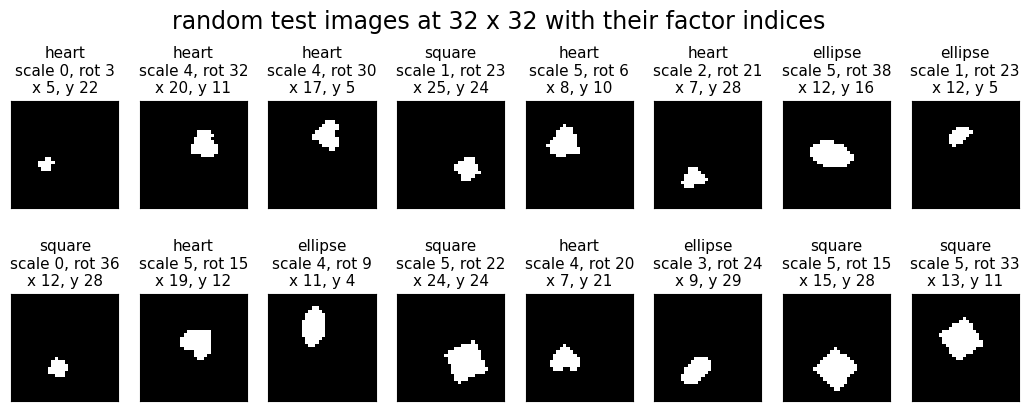

large centred square, fraction of pixels that differ from angle 0: at 92.3° 0.0000, at 46.2° 0.0303, at 360.0° 0.0000


In [5]:
# one training sample at 32 x 32: the pixel values around the sprite
x0 = sub["x"][N_TRAIN + 3]; r0, c0 = np.argwhere(x0).mean(0).round().astype(int)
print("factors (shape, scale, orientation, x, y):", Cte[3], " values:", np.round(Vte[3], 3))
print(x0[max(r0 - 6, 0):r0 + 6, max(c0 - 6, 0):c0 + 6])
fig, axs = plt.subplots(2, 8, figsize=(13, 4.6))
for a, i in zip(axs.flat, range(16)):
    a.imshow(Xte[i, 0], cmap="gray", vmin=0, vmax=1); a.set_xticks([]); a.set_yticks([])
    s, sc, o, px, py = Cte[i]
    a.set_title(f"{SHAPES[s]}\nscale {sc}, rot {o}\nx {px}, y {py}", fontsize=11)
plt.suptitle("random test images at 32 x 32 with their factor indices", y=1.02); plt.show()
sym, ang = sub["sym"], np.degrees(sub["angles"])
print(f"large centred square, fraction of pixels that differ from angle 0: at {ang[10]:.1f}° {sym[10]:.4f}, "
      f"at {ang[5]:.1f}° {sym[5]:.4f}, at {ang[39]:.1f}° {sym[39]:.4f}")

In the printed patch of one sample the sprite is a blob of ones in a sea of zeros: on average only 4.5% of the $32\times32$ pixels are white. A model that places the sprite a few pixels off pays for the missed pixels and for the wrongly painted ones, which is why position is the first thing any of these models learns.

Orientation is the factor the image does not fully reveal. The last printed line compares a large centred square at angle 0 with the same square rotated: at $92.3^\circ$ not a single pixel differs, while at $46.2^\circ$ 3% of the canvas changes, and the angles $0$ and $2\pi$, both present in the list of 40, give identical images. The ellipse is symmetric under a half turn, so its images near angle $\pi$ nearly repeat those near 0. Several orientation labels therefore belong to the same image, and no encoder can recover them; any measured mutual information with orientation is limited by this, not only by the model.

## Encoder and decoder

The networks follow the convolutional design of Higgins et al. (2017) and Burgess et al. (2018), which use $4\times4$ kernels with stride 2, channel numbers 32–32–64–64, a dense layer of 256 units and ten latent coordinates for $64\times64$ inputs. With $32\times32$ inputs one strided convolution fewer reaches the same $4\times4$ feature map, so the encoder has three convolutional layers (32–32–64 channels), each halving the side of the image, from 32 to 16, 8 and 4 pixels. The 1024 numbers of the final $64\times4\times4$ maps pass through a dense layer of 256 units to 20 outputs, the ten means $\mu_k$ and the ten log-variances $\ln\sigma_k^2$ of equation (5).

The decoder mirrors the encoder with transposed convolutions and returns one logit $G_j(\mathbf z)$ per pixel $j$. Its sigmoid $\hat x_j$ is the probability that the pixel is white, which makes the decoder a product of Bernoulli distributions,
$$p_\theta(\mathbf x\,|\,\mathbf z)=\prod_{j=1}^{1024}\hat x_j^{\,x_j}\,(1-\hat x_j)^{1-x_j},\qquad \hat x_j=\operatorname{sigmoid}\big(G_j(\mathbf z)\big), \tag{8}$$
and its negative logarithm the binary cross-entropy summed over the pixels,
$$-\log p_\theta(\mathbf x\,|\,\mathbf z)=-\sum_{j=1}^{1024}\big[x_j\ln\hat x_j+(1-x_j)\ln(1-\hat x_j)\big]. \tag{9}$$

In [6]:
d = 10                                                            # latent coordinates

class ConvVAE(nn.Module):
    # convolutional VAE for 1 x 32 x 32 binary images; d latent coordinates; Bernoulli decoder
    def __init__(self, d=10):
        super().__init__()
        self.d = d
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, 4, 2, 1), nn.ReLU(),                 # 1 x 32 x 32  -> 32 x 16 x 16
            nn.Conv2d(32, 32, 4, 2, 1), nn.ReLU(),                # 32 x 16 x 16 -> 32 x 8 x 8
            nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(),                # 32 x 8 x 8   -> 64 x 4 x 4
            nn.Flatten(), nn.Linear(1024, 256), nn.ReLU(),
            nn.Linear(256, 2 * d))                                # mu and log sigma^2
        self.decoder = nn.Sequential(
            nn.Linear(d, 256), nn.ReLU(), nn.Linear(256, 1024), nn.ReLU(),
            nn.Unflatten(1, (64, 4, 4)),
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(),       # -> 32 x 8 x 8
            nn.ConvTranspose2d(32, 32, 4, 2, 1), nn.ReLU(),       # -> 32 x 16 x 16
            nn.ConvTranspose2d(32, 1, 4, 2, 1))                   # -> 1 x 32 x 32 logits
    def encode(self, x):
        mu, logvar = self.encoder(x).chunk(2, dim=1); return mu, logvar
    def decode(self, z):
        return self.decoder(z)
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)   # reparametrisation trick
        return self.decode(z), mu, logvar

print(f"parameters: {sum(p.numel() for p in ConvVAE(d).parameters()):,}")

parameters: 633,045


`torchinfo` lists the network layer by layer with output shapes and parameter counts; the total is checked against a direct count of the trainable weights.

In [7]:
from torchinfo import summary
conv_vae = ConvVAE(d)
info = summary(conv_vae, input_size=(1, 1, 32, 32), col_names=("output_size", "num_params"), depth=2, verbose=0)
print(info)
n_conv = sum(p.numel() for p in conv_vae.parameters())
assert info.total_params == n_conv == 633_045, (info.total_params, n_conv)
nums["conv_vae_parameters"] = int(n_conv)

Layer (type:depth-idx)                   Output Shape              Param #
ConvVAE                                  [1, 1, 32, 32]            --
├─Sequential: 1-1                        [1, 20]                   --
│    └─Conv2d: 2-1                       [1, 32, 16, 16]           544
│    └─ReLU: 2-2                         [1, 32, 16, 16]           --
│    └─Conv2d: 2-3                       [1, 32, 8, 8]             16,416
│    └─ReLU: 2-4                         [1, 32, 8, 8]             --
│    └─Conv2d: 2-5                       [1, 64, 4, 4]             32,832
│    └─ReLU: 2-6                         [1, 64, 4, 4]             --
│    └─Flatten: 2-7                      [1, 1024]                 --
│    └─Linear: 2-8                       [1, 256]                  262,400
│    └─ReLU: 2-9                         [1, 256]                  --
│    └─Linear: 2-10                      [1, 20]                   5,140
├─Sequential: 1-2                        [1, 1, 32, 32]            -

The same information as a block diagram, one block per stage, read off the model itself: a forward pass with hooks on every layer records the output shape and the number of parameters of each stage, and the height of a block grows with the logarithm of the number of values it holds, so that the narrowing towards the ten latent coordinates and the widening back to the image are visible. Encoder and decoder are drawn in two rows; the sampling step of the reparametrisation trick closes the first row.

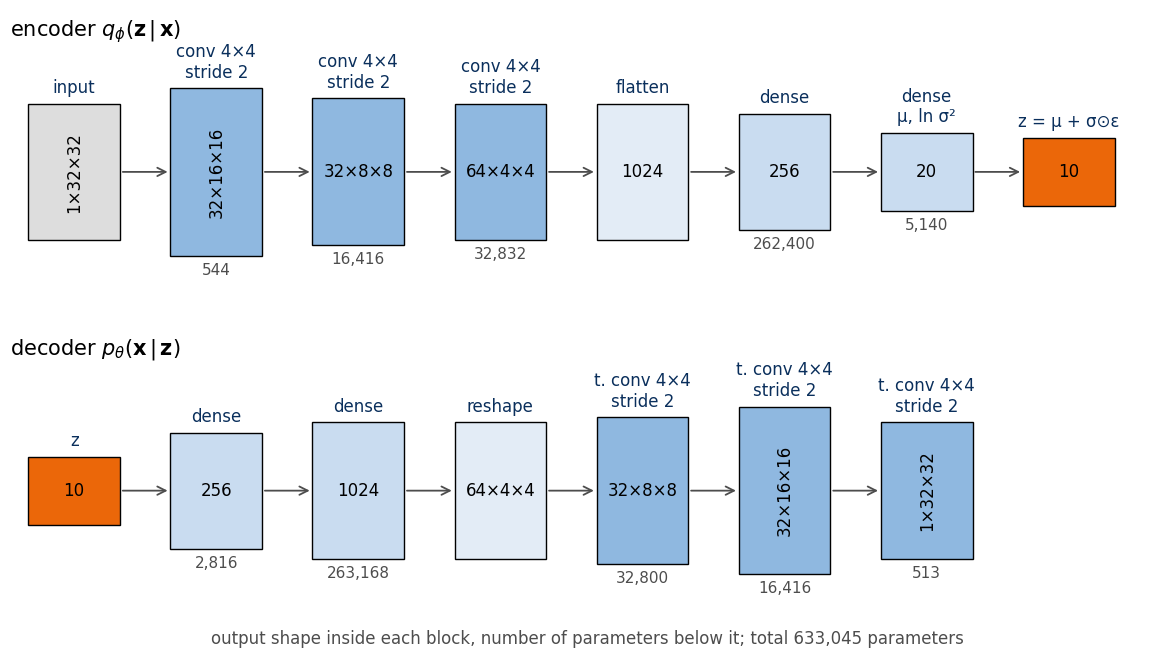

In [8]:
def layer_stages(model, x):
    """
    Record one stage per layer of model.encode and model.decode.

    model : a VAE with methods encode(x) -> (mu, logvar) and decode(z)
    x     : one input batch, e.g. torch.zeros(1, 1, 32, 32)
    Returns two lists (encoder, decoder) of dicts with keys
      name   short description of the layer (type, kernel, stride)
      shape  output shape without the batch dimension
      params number of trainable parameters of the layer
    """
    names = {nn.Conv2d: "conv", nn.ConvTranspose2d: "t. conv", nn.Linear: "dense",
             nn.Flatten: "flatten", nn.Unflatten: "reshape"}
    record = []
    def hook(m, inp, out):
        n = names[type(m)]
        if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
            n += f" {m.kernel_size[0]}×{m.kernel_size[1]}\nstride {m.stride[0]}"
        record.append(dict(name=n, shape=tuple(out.shape[1:]), params=sum(p.numel() for p in m.parameters())))
    hs = [m.register_forward_hook(hook) for m in model.modules() if type(m) in names]
    with torch.no_grad():
        mu, _ = model.encode(x); enc_stages = list(record); record.clear()
        model.decode(torch.zeros_like(mu)); dec_stages = list(record)
    for h in hs: h.remove()
    first = dict(name="input", shape=tuple(x.shape[1:]), params=0)
    enc_stages[-1]["name"] = "dense\nμ, ln σ²"                    # the last encoder layer gives the 2d numbers
    latent = dict(name="z = μ + σ⊙ε", shape=(mu.shape[1],), params=0, latent=True)
    return [first] + enc_stages + [latent], [dict(latent, name="z")] + dec_stages

def draw_blocks(ax, stages, title="", width=1.0, gap=0.55, colors=None):
    """
    Draw a list of stages as a row of blocks joined by arrows.

    ax     : matplotlib axes to draw on
    stages : list of dicts from layer_stages (keys name, shape, params, optional latent)
    title  : title written above the row
    width  : width of one block in axis units
    gap    : horizontal space between neighbouring blocks (holds the arrow)
    colors : dict mapping the first word of a stage name to a face colour
    """
    colors = colors or {"input": "#DDDDDD", "conv": "#8FB8E0", "t.": "#8FB8E0", "flatten": "#E3ECF6",
                        "reshape": "#E3ECF6", "dense": "#C9DCF0", "z": orange}
    hmax = max(np.log2(np.prod(s["shape"])) for s in stages)
    for i, s in enumerate(stages):
        x0 = i * (width + gap)
        h = 0.6 + 2.4 * np.log2(np.prod(s["shape"])) / hmax   # height grows with log2 of the number of values
        key = "z" if s.get("latent") else s["name"].split()[0]
        ax.add_patch(Rectangle((x0, -h / 2), width, h, fc=colors.get(key, "#C9DCF0"), ec="k", lw=1))
        # output shape inside the block, layer description above, parameter count below
        shp = "×".join(str(v) for v in s["shape"])
        ax.text(x0 + width / 2, 0, shp, ha="center", va="center", fontsize=12, rotation=90 if len(shp) > 6 else 0)
        ax.text(x0 + width / 2, h / 2 + 0.12, s["name"], ha="center", va="bottom", fontsize=12, color=navy)
        if s["params"]:
            ax.text(x0 + width / 2, -h / 2 - 0.12, f"{s['params']:,}", ha="center", va="top", fontsize=11, color="0.3")
        if i > 0:
            ax.annotate("", xy=(x0, 0), xytext=(x0 - gap, 0), arrowprops=dict(arrowstyle="->", lw=1.3, color="0.3"))
    ax.set_xlim(-0.2, len(stages) * (width + gap)); ax.set_ylim(-2.4, 2.9)
    ax.axis("off")
    if title: ax.text(-0.2, 2.75, title, fontsize=15, ha="left", va="top")

enc_st, dec_st = layer_stages(conv_vae, torch.zeros(1, 1, 32, 32))
assert sum(s["params"] for s in enc_st + dec_st) == n_conv        # every parameter belongs to one drawn stage
fig, axs = plt.subplots(2, 1, figsize=(12, 6.6))
draw_blocks(axs[0], enc_st, title=r"encoder $q_\phi(\mathbf{z}\,|\,\mathbf{x})$")
draw_blocks(axs[1], dec_st, title=r"decoder $p_\theta(\mathbf{x}\,|\,\mathbf{z})$")
for a in axs: a.set_xlim(-0.2, max(len(enc_st), len(dec_st)) * 1.55)
fig.text(0.5, 0.005, f"output shape inside each block, number of parameters below it; total {n_conv:,} parameters",
         ha="center", fontsize=12, color="0.3")
plt.tight_layout(); plt.savefig(f"{OUT}/beta_vae_arch.png", dpi=200, bbox_inches="tight"); plt.show()

`torchview` draws the computational graph of the same model.

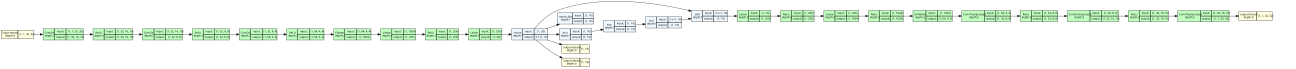

In [9]:
from torchview import draw_graph
graph = draw_graph(ConvVAE(d), input_size=(1, 1, 32, 32), depth=2, expand_nested=False, graph_dir="LR", save_graph=False)
graph.visual_graph.render(f"{RES}/beta_vae_torchview", format="png", cleanup=True)
graph.visual_graph

## Training

The loss (4) is averaged over a mini-batch of 128 images, with one sample $\mathbf z$ per image for the reconstruction term (9) and the KL term computed from equations (6) and (7). Every model sees the same 8,000 mini-batches (1,024,000 images, about ten passes over the 100,000 training images), with the Adam optimiser at learning rate $10^{-3}$ and the same seed, so that $\beta$ is the only difference between the runs. Three values are trained: β of 1 (the VAE), 4 (the value used for dSprites by Higgins et al.) and 8. During training the per-coordinate $\mathrm{KL}_k$ of each batch is recorded every 20 steps. The weights and the training history are saved in `results/` and reloaded if present.

Eight thousand steps is short by the standards of the literature, where dSprites models are trained for hundreds of thousands of steps; it is what a CPU allows in a few minutes per model, and all measurements refer to these short runs.

In [10]:
BETAS = [1, 4, 8]
STEPS, BS, LR = 8000, 128, 1e-3

def beta_vae_loss(logits, x, mu, logvar, beta):
    # per image: Bernoulli reconstruction term + beta * sum_k KL_k
    rec = F.binary_cross_entropy_with_logits(logits, x, reduction="sum") / len(x)
    kl_k = 0.5 * (mu ** 2 + logvar.exp() - logvar - 1).mean(0)    # KL per coordinate, averaged over the batch
    return rec + beta * kl_k.sum(), rec, kl_k

def train_beta_vae(beta, steps=STEPS, bs=BS, lr=LR, seed_=0):
    seed(seed_); model = ConvVAE(d); opt = torch.optim.Adam(model.parameters(), lr)
    g = torch.Generator().manual_seed(seed_)                      # same mini-batches for every beta
    hist = {"step": [], "rec": [], "kl": []}
    for s in range(steps):
        x = Xtr[torch.randint(0, len(Xtr), (bs,), generator=g)]
        logits, mu, logvar = model(x)
        loss, rec, kl_k = beta_vae_loss(logits, x, mu, logvar, beta)
        opt.zero_grad(); loss.backward(); opt.step()
        if s % 20 == 0 or s == steps - 1:
            hist["step"].append(s); hist["rec"].append(rec.item()); hist["kl"].append(kl_k.detach().numpy())
        if s % 2000 == 0 or s == steps - 1:
            print(f"  beta = {beta}, step {s:4d}: reconstruction {rec.item():6.1f}, KL {kl_k.sum().item():5.2f} nats")
    return model.eval(), {k: np.array(v) for k, v in hist.items()}

models, hists = {}, {}
for beta in BETAS:
    w, h = f"{RES}/beta_vae_dsprites_beta{beta}.pt", f"{RES}/beta_vae_dsprites_beta{beta}_history.npz"
    if os.path.exists(w) and os.path.exists(h):
        m = ConvVAE(d); m.load_state_dict(torch.load(w)); models[beta] = m.eval()
        hists[beta] = dict(np.load(h)); print(f"beta = {beta}: weights loaded from {w}")
    else:
        t0 = time.time()
        models[beta], hists[beta] = train_beta_vae(beta)
        torch.save(models[beta].state_dict(), w); np.savez(h, **hists[beta])
        print(f"beta = {beta}: trained in {time.time() - t0:.0f} s")

beta = 1: weights loaded from results/beta_vae_dsprites_beta1.pt
beta = 4: weights loaded from results/beta_vae_dsprites_beta4.pt
beta = 8: weights loaded from results/beta_vae_dsprites_beta8.pt


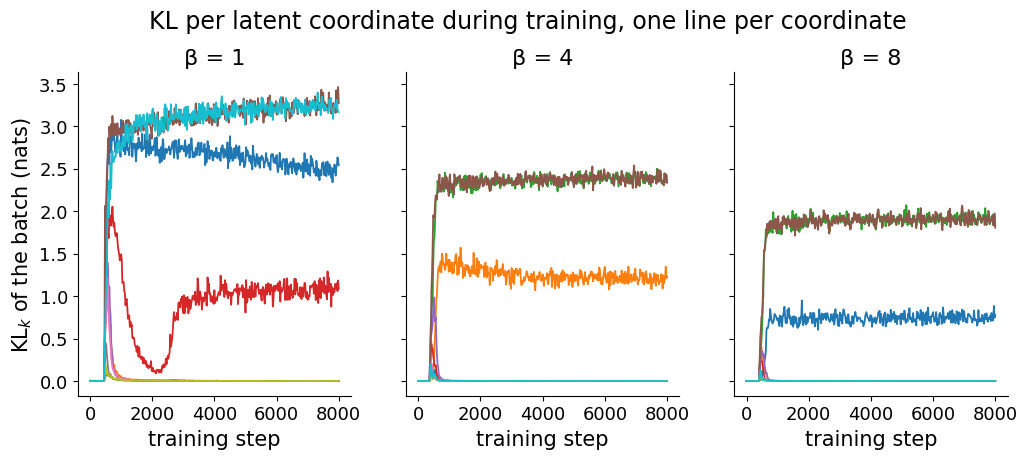

In [11]:
fig, axs = plt.subplots(1, len(BETAS), figsize=(12, 4.2), sharey=True)
for ax, beta in zip(axs, BETAS):
    h = hists[beta]
    for k in range(d): ax.plot(h["step"], h["kl"][:, k], lw=1.3)
    ax.set_title(f"β = {beta}"); ax.set_xlabel("training step"); clean(ax)
axs[0].set_ylabel(r"KL$_k$ of the batch (nats)")
plt.suptitle("KL per latent coordinate during training, one line per coordinate", y=1.03)
plt.savefig(f"{OUT}/beta_vae_kl_training.png", dpi=200, bbox_inches="tight"); plt.show()

For the first 400 steps or so every coordinate has KL close to zero: the decoder learns the average image, a faint blob near the centre, and the encoder transmits nothing. Between steps 400 and 600 several coordinates switch on at once, and most of them collapse again within a few hundred steps. What survives depends on β. For β of 1 three coordinates settle near 3 nats and a fourth rises to 2 nats, decays almost to zero by step 2,000 and returns to about 1 nat after step 2,500, a late addition of a further factor. For β of 4 and 8 only three coordinates survive, two of them with equal KL (2.4 nats for β of 4, 1.9 for β of 8) and a third with less (1.2 and 0.75 nats). Two equal channels are what two factors of equal entropy would require; the alignment section identifies them as the two positions.

## KL per latent coordinate

The 10,000 test images are encoded and $\mathrm{KL}_k$ of equation (7) is averaged over them. A coordinate whose average KL is close to zero has zero mean and unit width for every input: it has collapsed onto the prior and the decoder ignores it. We call a coordinate active when its average KL exceeds 0.1 nats.

beta = 1: KL per coordinate (sorted) [3.3  3.23 2.52 1.09 0.   0.   0.   0.   0.   0.  ], total 10.15 nats, active 4


beta = 4: KL per coordinate (sorted) [2.4  2.37 1.2  0.   0.   0.   0.   0.   0.   0.  ], total 5.98 nats, active 3


beta = 8: KL per coordinate (sorted) [1.87 1.83 0.75 0.   0.   0.   0.   0.   0.   0.  ], total 4.46 nats, active 3


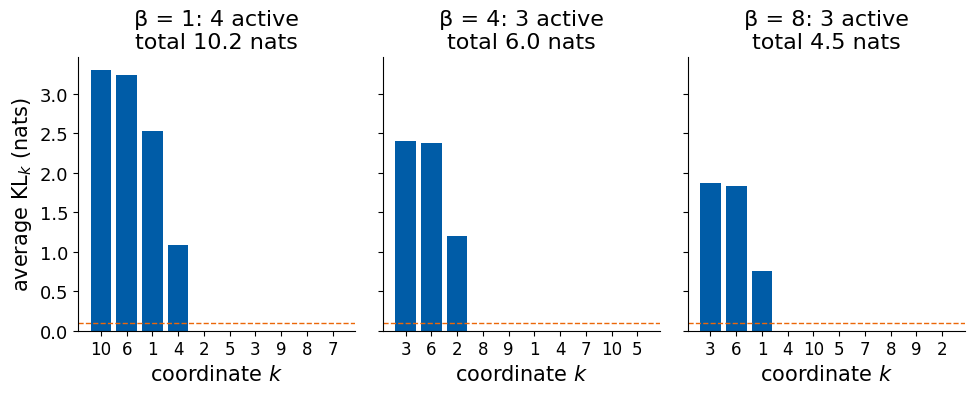

In [12]:
ACTIVE = 0.1                                                      # nats
enc = {}
with torch.no_grad():
    for beta in BETAS:
        mu, logvar = models[beta].encode(Xte)
        kl = (0.5 * (mu ** 2 + logvar.exp() - logvar - 1)).mean(0).numpy()
        rec = F.binary_cross_entropy_with_logits(models[beta].decode(mu), Xte, reduction="sum").item() / len(Xte)
        enc[beta] = dict(mu=mu.numpy(), sd=torch.exp(0.5 * logvar).numpy(), kl=kl, order=np.argsort(-kl), rec=rec)
        nums[f"beta{beta}_kl_per_dim_sorted"] = [round(float(v), 3) for v in np.sort(kl)[::-1]]
        nums[f"beta{beta}_kl_total"] = round(float(kl.sum()), 2)
        nums[f"beta{beta}_n_active"] = int((kl > ACTIVE).sum())
        print(f"beta = {beta}: KL per coordinate (sorted) {np.round(np.sort(kl)[::-1], 2)}, total {kl.sum():.2f} nats, "
              f"active {int((kl > ACTIVE).sum())}")

fig, axs = plt.subplots(1, len(BETAS), figsize=(10, 4.2), sharey=True)
for ax, beta in zip(axs, BETAS):
    kl = enc[beta]["kl"]; o = enc[beta]["order"]
    ax.bar(range(d), kl[o], color=[blue if v > ACTIVE else grey for v in kl[o]])
    ax.set_xticks(range(d)); ax.set_xticklabels([str(k + 1) for k in o], fontsize=12); ax.set_xlabel("coordinate $k$")
    ax.set_title(f"β = {beta}: {int((kl > ACTIVE).sum())} active\ntotal {kl.sum():.1f} nats"); clean(ax)
axs[0].set_ylabel(r"average KL$_k$ (nats)")
for ax in axs: ax.axhline(ACTIVE, color=orange, lw=1, ls="--")
plt.tight_layout(); plt.savefig(f"{OUT}/beta_vae_kl_per_dim.png", dpi=200, bbox_inches="tight"); plt.show()

Of the ten available coordinates the VAE uses four, carrying 3.30, 3.23, 2.52 and 1.09 nats, 10.15 nats in total. With β of 4 three coordinates remain (2.40, 2.37 and 1.20 nats, total 5.98), and with β of 8 the same three shrink further (1.87, 1.83 and 0.75 nats, total 4.46). The extra coordinates are not needed to describe five factors at this resolution, and the price per nat in equation (4) decides how much information the remaining ones carry: going from β of 1 to β of 8 removes more than half of the transmitted information. All other coordinates have an average KL below 0.01 nats; they have collapsed onto the prior.

## Factor alignment

Since the factors $v_1,\dots,v_5$ of every test image are known, the alignment between latent coordinates and factors can be measured. Two quantities from information theory do it, and both are expectations of logarithms of probabilities, like the KL divergence of the β-VAE loss.

The entropy of a factor measures how uncertain its value is before anything is observed. An outcome $b$ of probability $p(b)$ carries the surprise $-\ln p(b)$: a certain outcome surprises by nothing, a rare one by much. The entropy $H(v_j)$ in the second line of equation (10) is the average surprise. For a factor whose $n$ values are equally likely it is the logarithm of $n$, the larger the more values have to be told apart. In dSprites the shape takes three values and has an entropy of 1.10 nats, the scale six values and 1.79 nats, each position 32 values and 3.47 nats, and the orientation 40 values and 3.69 nats.

The mutual information $I(z_k;v_j)$ in the first line of equation (10) measures how much of this uncertainty disappears once the coordinate $z_k$ is known: it is the entropy of the factor minus the conditional entropy, the uncertainty about the factor that remains after reading the coordinate. Written out, it is the KL divergence between the joint distribution $p(a,b)$ and the product $p(a)\,p(b)$ that the two variables would have if they were independent. It is therefore zero exactly when the coordinate and the factor are independent, and it reaches $H(v_j)$ when the coordinate determines the factor completely. Unlike a correlation coefficient, it also detects relations that are not linear or not monotonic, for example a coordinate that encodes an angle on a circle. For each pair of a coordinate $z_k$ and a factor $v_j$ we estimate
$$I(z_k;v_j)=\sum_{a,b}p(a,b)\,\ln\frac{p(a,b)}{p(a)\,p(b)},\qquad H(v_j)=-\sum_b p(b)\ln p(b), \tag{10}$$
where $a$ runs over 20 equal-width bins of the posterior mean $\mu_k$ over the test set and $b$ over the values of $v_j$; the probabilities are frequencies in the 10,000 test images. Since equation (10) cannot exceed the entropy $H(v_j)$ of the factor, the normalised mutual information
$$\tilde I(z_k;v_j)=\frac{I(z_k;v_j)}{H(v_j)} \tag{11}$$
lies between 0 (the coordinate says nothing about the factor) and 1 (it determines the factor), and it can be read as the fraction of the uncertainty about the factor that the coordinate removes. For a disentangled representation the matrix of these values has one large entry per factor, each in a different row.

The mutual information gap (MIG) of Chen et al. (2018) condenses the matrix into one number. For each factor it takes the normalised mutual information of the most informative coordinate, $z_{(1)}$, minus that of the second most informative one, $z_{(2)}$, and averages over the $K$ factors:
$$\mathrm{MIG}=\frac1K\sum_{j=1}^{K}\Big[\tilde I\big(z_{(1)};v_j\big)-\tilde I\big(z_{(2)};v_j\big)\Big]. \tag{12}$$
A factor captured by one coordinate scores close to its normalised mutual information. A factor smeared over two coordinates, say 0.35 and 0.30, scores 0.05 even if the representation contains it completely; so does a factor copied into two coordinates, 0.60 and 0.60, which a score based on the largest value alone would reward. The gap rewards exactly what disentanglement asks for: one coordinate per factor, and only one. The measure needs the true factors of every image, which is why it is computed on synthetic data such as dSprites; for real data such as galaxy images, where the causes are unknown, only correlations with measured properties remain. Chen et al. estimate the mutual information by sampling from $q_\phi(\mathbf z\,|\,\mathbf x)$; we use the binned means, a common simplification.

A complementary question is how much each factor is present in the representation at all, irrespective of alignment. A linear probe answers it: a logistic regression predicting the shape from the ten means (accuracy, chance level one third) and linear regressions predicting the scale and the two positions (coefficient of determination $R^2$), fitted on 8,000 test images and evaluated on the other 2,000. Orientation is left out of the probe, since the image does not determine it for the symmetric shapes.

In [13]:
from sklearn.metrics import mutual_info_score
from sklearn.linear_model import LogisticRegression, LinearRegression

def discretise(m, bins=20):
    edges = np.linspace(m.min(), m.max(), bins + 1)[1:-1]
    return np.digitize(m, edges)

def mi_matrix(mu, factors):
    # normalised mutual information I(z_k; v_j) / H(v_j), shape (d, K)
    H = np.array([mutual_info_score(factors[:, j], factors[:, j]) for j in range(factors.shape[1])])
    M = np.array([[mutual_info_score(discretise(mu[:, k]), factors[:, j]) for j in range(factors.shape[1])]
                  for k in range(mu.shape[1])])
    return M / H, H

def mig(nmi):
    s = np.sort(nmi, axis=0)
    return s[-1] - s[-2]                                          # gap per factor

def probes(mu, factors, n_fit=8000):
    out = {}
    clf = LogisticRegression(max_iter=2000).fit(mu[:n_fit], factors[:n_fit, 0])
    out["shape (accuracy)"] = clf.score(mu[n_fit:], factors[n_fit:, 0])
    for j, name in [(1, "scale"), (3, "position x"), (4, "position y")]:
        reg = LinearRegression().fit(mu[:n_fit], factors[:n_fit, j])
        out[f"{name} (R^2)"] = reg.score(mu[n_fit:], factors[n_fit:, j])
    return out

for beta in BETAS:
    e = enc[beta]
    e["nmi"], H = mi_matrix(e["mu"], Cte)
    e["corr"] = np.abs(np.corrcoef(np.c_[e["mu"], Cte].T)[:d, d:])
    e["mig"] = mig(e["nmi"]); e["probe"] = probes(e["mu"], Cte)
    nums[f"beta{beta}_mig"] = round(float(e["mig"].mean()), 3)
    nums[f"beta{beta}_nmi_rows_by_kl"] = {f"z{k + 1}": [round(float(v), 2) for v in e["nmi"][k]] for k in np.argsort(-e["kl"])}
    nums[f"beta{beta}_mig_per_factor"] = dict(zip(FACTORS, [round(float(v), 3) for v in e["mig"]]))
    nums[f"beta{beta}_probe"] = {k: round(float(v), 3) for k, v in e["probe"].items()}
    print(f"beta = {beta}: MIG = {e['mig'].mean():.3f};  per factor", dict(zip(FACTORS, np.round(e["mig"], 3))))
    print("           probe:", {k: round(v, 3) for k, v in e["probe"].items()})
print("entropies H(v_j) in nats:", dict(zip(FACTORS, np.round(H, 3))))

beta = 1: MIG = 0.150;  per factor {'shape': np.float64(0.324), 'scale': np.float64(0.071), 'orientation': np.float64(0.11), 'position x': np.float64(0.116), 'position y': np.float64(0.129)}
           probe: {'shape (accuracy)': 0.493, 'scale (R^2)': 0.47, 'position x (R^2)': 0.929, 'position y (R^2)': 0.942}
beta = 4: MIG = 0.295;  per factor {'shape': np.float64(0.111), 'scale': np.float64(0.305), 'orientation': np.float64(0.001), 'position x': np.float64(0.542), 'position y': np.float64(0.516)}
           probe: {'shape (accuracy)': 0.448, 'scale (R^2)': 0.807, 'position x (R^2)': 0.971, 'position y (R^2)': 0.973}


beta = 8: MIG = 0.301;  per factor {'shape': np.float64(0.134), 'scale': np.float64(0.322), 'orientation': np.float64(0.006), 'position x': np.float64(0.494), 'position y': np.float64(0.548)}
           probe: {'shape (accuracy)': 0.442, 'scale (R^2)': 0.816, 'position x (R^2)': 0.974, 'position y (R^2)': 0.978}
entropies H(v_j) in nats: {'shape': np.float64(1.099), 'scale': np.float64(1.792), 'orientation': np.float64(3.687), 'position x': np.float64(3.465), 'position y': np.float64(3.464)}


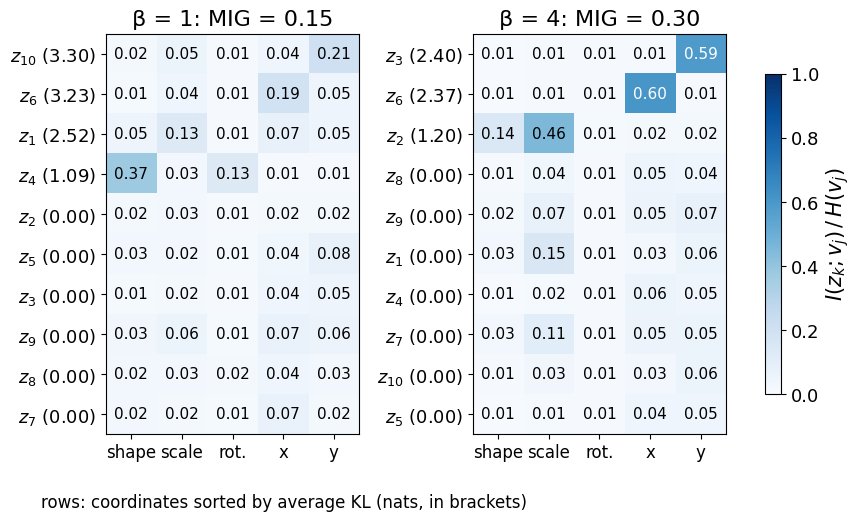

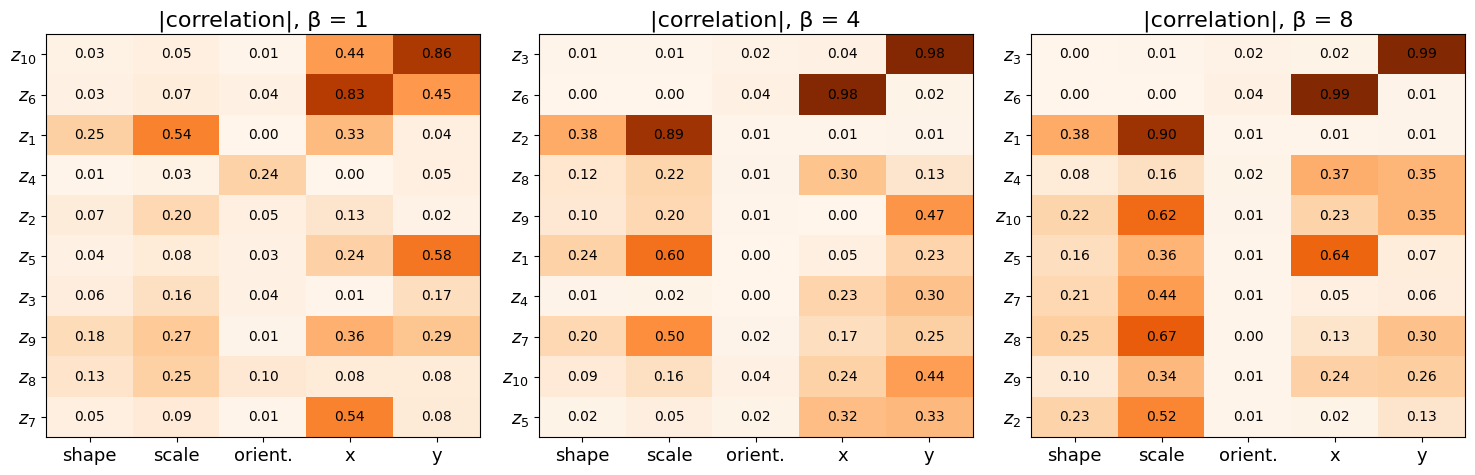

In [14]:
def factor_label(nmi_row, kl_k):
    # name of the factor a coordinate aligns with, if the alignment is clear
    if kl_k < ACTIVE: return "inactive"
    j = np.argmax(nmi_row); s = np.sort(nmi_row)
    return FACTORS[j] if (s[-1] >= 0.2 and s[-1] >= 2 * s[-2]) else "mixed"

for beta in BETAS:
    e = enc[beta]; e["labels"] = [factor_label(e["nmi"][k], e["kl"][k]) for k in range(d)]

fig, axs = plt.subplots(1, 2, figsize=(10, 5.2), gridspec_kw={"wspace": 0.45})
for ax, beta in zip(axs, [1, 4]):
    e = enc[beta]; o = e["order"]
    im = ax.imshow(e["nmi"][o], cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for r, k in enumerate(o):
        for j in range(len(FACTORS)):
            v = e["nmi"][k, j]
            ax.text(j, r, f"{v:.2f}", ha="center", va="center", fontsize=11, color="white" if v > 0.55 else "black")
    ax.set_xticks(range(len(FACTORS))); ax.set_xticklabels(["shape", "scale", "rot.", "x", "y"], fontsize=12)
    ax.set_yticks(range(d)); ax.set_yticklabels([f"$z_{{{k + 1}}}$ ({e['kl'][k]:.2f})" for k in o], fontsize=13)
    ax.set_title(f"β = {beta}: MIG = {e['mig'].mean():.2f}")
fig.colorbar(im, ax=axs, shrink=0.8, label=r"$I(z_k; v_j)\,/\,H(v_j)$")
fig.text(0.06, -0.03, "rows: coordinates sorted by average KL (nats, in brackets)", fontsize=12)
plt.savefig(f"{OUT}/beta_vae_factor_matrix.png", dpi=200, bbox_inches="tight"); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, beta in zip(axs, BETAS):
    e = enc[beta]; o = e["order"]
    ax.imshow(e["corr"][o], cmap="Oranges", vmin=0, vmax=1, aspect="auto")
    for r, k in enumerate(o):
        for j in range(len(FACTORS)):
            ax.text(j, r, f"{e['corr'][k, j]:.2f}", ha="center", va="center", fontsize=10)
    ax.set_xticks(range(len(FACTORS))); ax.set_xticklabels(["shape", "scale", "orient.", "x", "y"])
    ax.set_yticks(range(d)); ax.set_yticklabels([f"$z_{{{k + 1}}}$" for k in o]); ax.set_title(f"|correlation|, β = {beta}")
plt.tight_layout(); plt.show()

The mutual information gap doubles between the VAE and the β-VAE: 0.150 for β of 1, 0.295 for β of 4 and 0.301 for β of 8. The matrix for β of 4 is nearly diagonal in its three active rows: one coordinate determines position $x$ (normalised mutual information 0.60), one position $y$ (0.59) and one the scale (0.46), and each of them carries almost nothing about the other factors. In the VAE the same information is spread out. Its most informative coordinate about $y$ reaches only 0.21 and the one about $x$ 0.19, yet the linear probe recovers both positions almost as well as from the β-VAE ($R^2$ of 0.93 and 0.94, against 0.97 and 0.97). The VAE has the information; it stores it in rotated, mixed axes. Disentanglement is a property of the arrangement of the code, not of its content.

Shape and orientation are where both models fall short. The VAE spends its fourth coordinate on a mixture of shape (0.37) and orientation (0.13), which gives it the best shape score of the three models (gap 0.32 for shape); the β-VAEs cannot afford that coordinate and keep only a trace of shape in the scale coordinate (0.14 for β of 4). Shape is classified from the means with accuracy 0.49, 0.45 and 0.44 for β of 1, 4 and 8, above the chance level of one third but far from perfect, and orientation is essentially absent (gap at most 0.11). At $32\times32$ a sprite covers a few dozen pixels, the difference between a square, an ellipse and a heart is a handful of them, and under a price per nat these details are the first to go.

Collapsed coordinates show values up to 0.15 in these matrices (0.19 for β of 8). Their means are almost constant, but the 20 bins of equation (10) are spread over each coordinate's own tiny range, so residual variations of the encoder output still correlate with the factors although the decoder ignores them. Values of this size are the noise floor of the estimate.

## Latent traversals

A traversal makes a coordinate visible. One test image is encoded to its mean $\boldsymbol\mu(\mathbf x)$; then a single coordinate $z_k$ is moved from $-3$ to $3$ while the other nine stay at their encoded values, and each point is decoded. Rows are coordinates sorted by their average KL, and each row is labelled with the factor it aligns with according to the alignment matrix (a normalised mutual information (11) of at least 0.2 and at least twice the second largest in the row), "mixed" otherwise, and "off" below 0.1 nats.

seed image factors: {'shape': 2, 'scale': 3, 'orientation': 23, 'position x': 15, 'position y': 14}


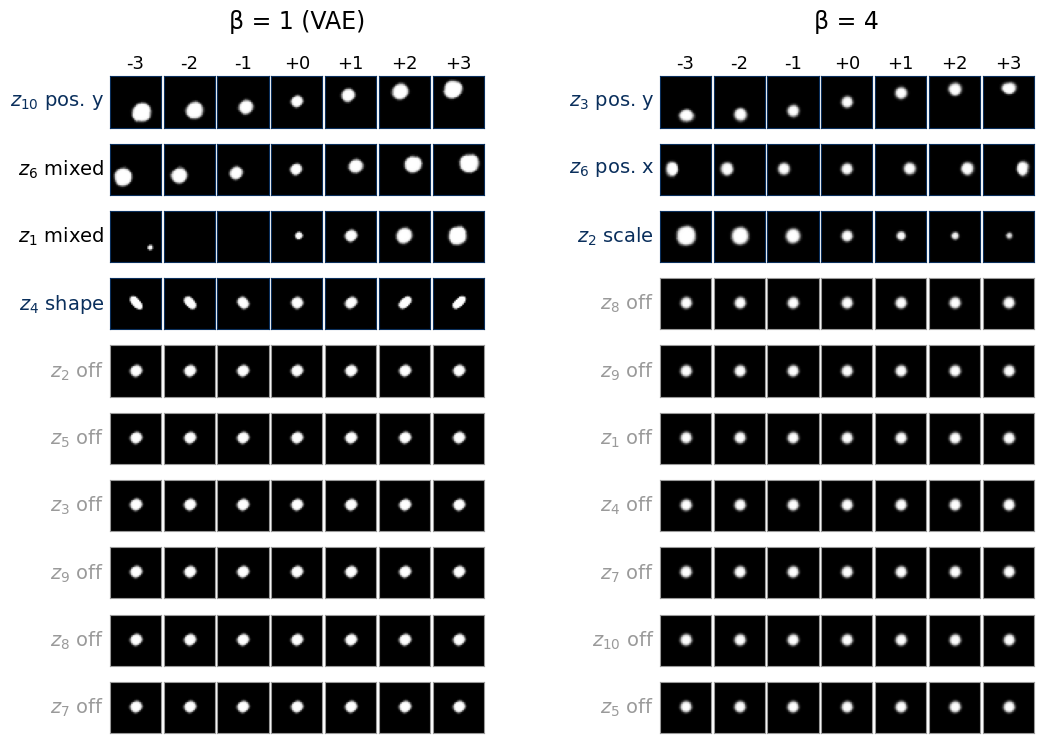

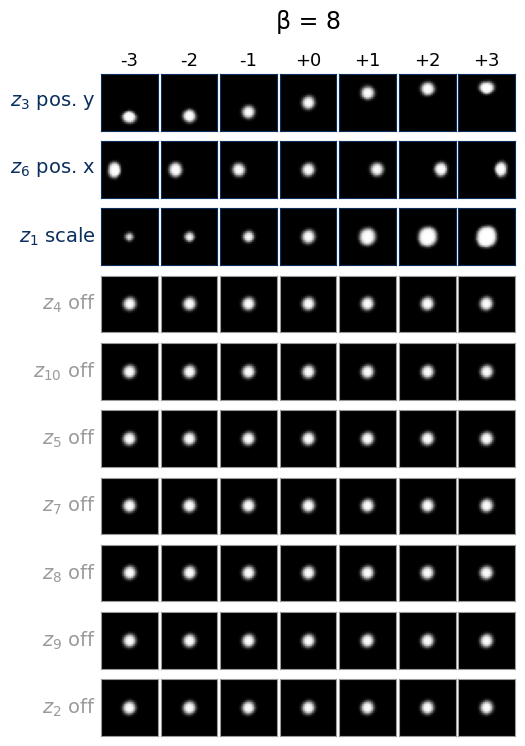

In [15]:
ZS = np.linspace(-3, 3, 7)
# seed image: a heart of medium scale near the centre of the canvas, so that traversals stay inside it
cand = np.where((Cte[:, 0] == 2) & (Cte[:, 1] == 3) & (np.abs(Cte[:, 3] - 16) <= 3) & (np.abs(Cte[:, 4] - 16) <= 3))[0]
i_seed = int(cand[0]); nums["traversal_seed_factors"] = dict(zip(FACTORS, [int(v) for v in Cte[i_seed]]))
print("seed image factors:", nums["traversal_seed_factors"])

def traversal(model, x, order, zs=ZS):
    with torch.no_grad():
        mu, _ = model.encode(x[None])
        rows = []
        for k in order:
            z = mu.repeat(len(zs), 1); z[:, k] = torch.tensor(zs, dtype=torch.float32)
            rows.append(torch.sigmoid(model.decode(z))[:, 0].numpy())
    return np.array(rows)                                          # (rows, len(zs), 32, 32)

def draw_traversal(fig, gs, beta, title):
    e = enc[beta]; T = traversal(models[beta], Xte[i_seed], e["order"])
    for r, k in enumerate(e["order"]):
        for c in range(len(ZS)):
            ax = fig.add_subplot(gs[r, c]); ax.imshow(T[r, c], cmap="gray", vmin=0, vmax=1); ax.set_xticks([]); ax.set_yticks([])
            for s in ax.spines.values(): s.set_color(grey if e["kl"][k] < ACTIVE else navy)
            if c == 0:
                lab = e["labels"][k]
                ax.set_ylabel(f"$z_{{{k + 1}}}$ {SHORT.get(lab, lab)}", rotation=0, ha="right", va="center", fontsize=14,
                              color=grey if lab == "inactive" else ("black" if lab == "mixed" else navy))
            if r == 0: ax.set_title(f"{ZS[c]:+.0f}", fontsize=13)
    l, rr_ = gs.get_grid_positions(fig)[2][0], gs.get_grid_positions(fig)[3][-1]
    fig.text((l + rr_) / 2, 0.955, title, fontsize=17, ha="center")

from matplotlib.gridspec import GridSpec
SHORT = {"position x": "pos. x", "position y": "pos. y", "orientation": "orient.", "inactive": "off"}
fig = plt.figure(figsize=(11, 7.6))
draw_traversal(fig, GridSpec(d, 7, left=0.14, right=0.48, top=0.9, bottom=0.02, wspace=0.05, hspace=0.06), 1, "β = 1 (VAE)")
draw_traversal(fig, GridSpec(d, 7, left=0.64, right=0.98, top=0.9, bottom=0.02, wspace=0.05, hspace=0.06), 4, "β = 4")
plt.savefig(f"{OUT}/beta_vae_traversals.png", dpi=200, bbox_inches="tight"); plt.show()

fig = plt.figure(figsize=(6, 7.6))
draw_traversal(fig, GridSpec(d, 7, left=0.28, right=0.97, top=0.9, bottom=0.02, wspace=0.05, hspace=0.06), 8, "β = 8")
plt.show()

For β of 4 the three active rows do what the matrix says: one coordinate moves the sprite vertically, one horizontally, and one changes its size from large to a dot, each leaving the other properties of the image in place. The seven collapsed rows do not change the image at all. The VAE rows are different. Its first coordinate moves the sprite upwards while also enlarging it, the second moves it along a diagonal while enlarging it, the third changes the size but empties the canvas for negative values, and the fourth stretches the blob into an ellipse and turns it, shape and orientation together. Each VAE coordinate changes several properties at once, which is what an entangled representation looks like. For β of 8 the picture is that of β of 4, with three clean rows (vertical position, horizontal position, scale) and slightly blurrier images. None of the models draws a recognisable square or heart: the decoded sprites are blobs, in line with the low shape scores.

## Reconstruction cost

The cost of a tighter bottleneck is measured by the reconstruction term (9) on the test set, in nats per image, with each image decoded from its mean $\boldsymbol\mu(\mathbf x)$. Next to it stands the total KL (6), the information the code carries.

beta = 1: reconstruction  20.56 nats per image, KL 10.15 nats, -ELBO (mean decoding)  30.71
beta = 4: reconstruction  26.79 nats per image, KL  5.98 nats, -ELBO (mean decoding)  32.77
beta = 8: reconstruction  30.57 nats per image, KL  4.46 nats, -ELBO (mean decoding)  35.03


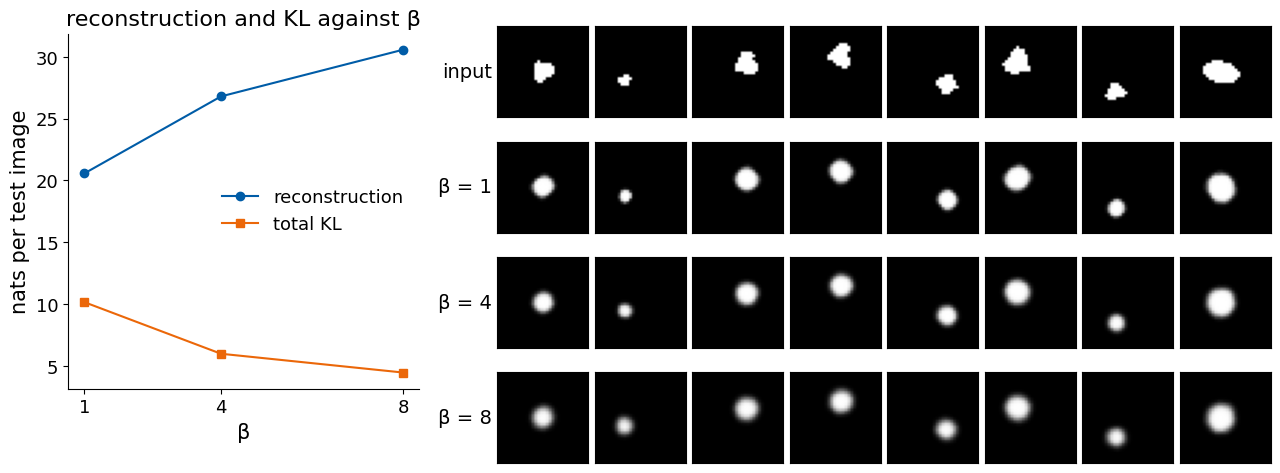

In [16]:
for beta in BETAS:
    nums[f"beta{beta}_test_reconstruction"] = round(enc[beta]["rec"], 2)
    print(f"beta = {beta}: reconstruction {enc[beta]['rec']:6.2f} nats per image, KL {enc[beta]['kl'].sum():5.2f} nats, "
          f"-ELBO (mean decoding) {enc[beta]['rec'] + enc[beta]['kl'].sum():6.2f}")

fig = plt.figure(figsize=(13, 4.8))
ax = fig.add_axes([0.05, 0.14, 0.27, 0.74])
ax.plot(BETAS, [enc[b]["rec"] for b in BETAS], "o-", color=blue, label="reconstruction")
ax.plot(BETAS, [enc[b]["kl"].sum() for b in BETAS], "s-", color=orange, label="total KL")
ax.set_xlabel("β"); ax.set_ylabel("nats per test image"); ax.set_xticks(BETAS); ax.legend(frameon=False); clean(ax)
ax.set_title("reconstruction and KL against β")
show = [i_seed] + list(range(7))
for r, row in enumerate(["input"] + [f"β = {b}" for b in BETAS]):
    for c, i in enumerate(show):
        a = fig.add_axes([0.38 + 0.075 * c, 0.69 - 0.24 * r, 0.07, 0.22])
        if r == 0: img = Xte[i, 0].numpy()
        else:
            with torch.no_grad(): img = torch.sigmoid(models[BETAS[r - 1]].decode(models[BETAS[r - 1]].encode(Xte[i:i + 1])[0]))[0, 0].numpy()
        a.imshow(img, cmap="gray", vmin=0, vmax=1); a.set_xticks([]); a.set_yticks([])
        if c == 0: a.set_ylabel(row, rotation=0, ha="right", va="center", fontsize=14)
plt.savefig(f"{OUT}/beta_vae_reconstruction.png", dpi=200, bbox_inches="tight"); plt.show()

The reconstruction term grows from 20.56 nats per test image for β of 1 to 26.79 for β of 4 and 30.57 for β of 8, while the KL term falls from 10.15 to 5.98 and 4.46 nats. Going from β of 1 to 4 saves 4.2 nats of information and costs 6.2 nats of reconstruction, so minus the ELBO of equation (2), evaluated with mean decoding, rises from 30.71 to 32.77 nats: as a model of the data the β-VAE is worse, which is the price of its cleaner axes. The decoded images show where the nats went. All three models put a blob of the right size at the right place, and none reproduces the corners of the square or the notch of the heart; with growing β the edges of the blob soften.

## Sampling

A trained VAE can be used in four ways, and they differ in which network is involved and what is random.

Generation uses the decoder alone. A code is drawn from the prior (1), the decoder turns it into the pixel probabilities $\hat{\mathbf x}(\mathbf z)$ of equation (8), and a pixel image is drawn from the Bernoulli distribution (8):
$$\mathbf z\sim\mathcal N(0,I),\qquad \mathbf x\sim p_\theta(\mathbf x\,|\,\mathbf z). \tag{13}$$
These two steps are ancestral sampling of the model distribution
$$p_\theta(\mathbf x)=\int p_\theta(\mathbf x\,|\,\mathbf z)\,p(\mathbf z)\,d\mathbf z . \tag{14}$$
The encoder plays no part. What is usually displayed, in the papers as in the figures that follow, is not the pixel sample but its mean, the array of probabilities $\hat{\mathbf x}(\mathbf z)$; one row of pixel samples makes the difference visible.

Reconstruction is a statement about a given image rather than about the distribution: $\mathbf x$ is encoded, a code is taken from $q_\phi(\mathbf z\,|\,\mathbf x)$ (its mean $\boldsymbol\mu(\mathbf x)$), and decoded. Traversals start from such a code and move one coordinate. Interpolation encodes two images $\mathbf x_a$ and $\mathbf x_b$ to their means $\boldsymbol\mu_a$ and $\boldsymbol\mu_b$ and decodes the straight path between them,
$$\mathbf z(t)=\boldsymbol\mu_a+t\,(\boldsymbol\mu_b-\boldsymbol\mu_a),\qquad 0\le t\le1; \tag{15}$$
whether the intermediate images are plausible depends on whether the path stays where the decoder was trained.

As a number for the blur of a decoded image we use the mean per-pixel Bernoulli entropy,
$$h=-\frac1{N_{\mathrm{pix}}}\sum_{j=1}^{N_{\mathrm{pix}}}\big[\hat x_j\ln\hat x_j+(1-\hat x_j)\ln(1-\hat x_j)\big], \tag{16}$$
which is 0 when every pixel is decided and $\ln2$ (about 0.69 nats) when every pixel is a coin toss.

beta = 1: mean pixel entropy (nats) of generated images 0.0171, of reconstructions 0.0220
beta = 4: mean pixel entropy (nats) of generated images 0.0310, of reconstructions 0.0308
beta = 8: mean pixel entropy (nats) of generated images 0.0366, of reconstructions 0.0392


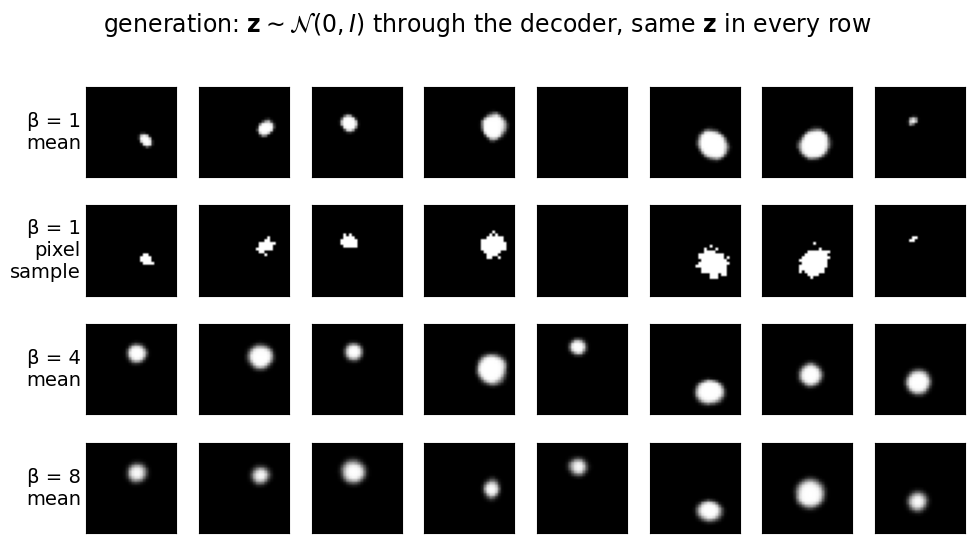

In [17]:
def pixel_entropy(p):
    p = p.clamp(1e-6, 1 - 1e-6)
    return float((-(p * p.log() + (1 - p) * (1 - p).log())).mean())

torch.manual_seed(7); Z = torch.randn(16, d)                      # the same 16 prior draws for every model
gen = {}
with torch.no_grad():
    for beta in BETAS:
        gen[beta] = torch.sigmoid(models[beta].decode(Z))[:, 0]    # mean images p(pixel white | z)
        rec_mean = torch.sigmoid(models[beta].decode(torch.tensor(enc[beta]["mu"][:1000])))[:, 0]
        nums[f"beta{beta}_pixel_entropy_generated"] = round(pixel_entropy(gen[beta]), 4)
        nums[f"beta{beta}_pixel_entropy_reconstructed"] = round(pixel_entropy(rec_mean), 4)
        print(f"beta = {beta}: mean pixel entropy (nats) of generated images {pixel_entropy(gen[beta]):.4f}, "
              f"of reconstructions {pixel_entropy(rec_mean):.4f}")
torch.manual_seed(8); bern = torch.bernoulli(gen[1][:8])           # one Bernoulli pixel sample per mean image

fig, axs = plt.subplots(4, 8, figsize=(10, 5.6))
rows = [(gen[1][:8], "β = 1\nmean"), (bern, "β = 1\npixel\nsample"), (gen[4][:8], "β = 4\nmean"), (gen[8][:8], "β = 8\nmean")]
for r, (imgs, lab) in enumerate(rows):
    for c in range(8):
        a = axs[r, c]; a.imshow(imgs[c], cmap="gray", vmin=0, vmax=1); a.set_xticks([]); a.set_yticks([])
        if c == 0: a.set_ylabel(lab, rotation=0, ha="right", va="center", fontsize=14)
plt.suptitle(r"generation: $\mathbf{z}\sim\mathcal{N}(0,I)$ through the decoder, same $\mathbf{z}$ in every row", y=0.99)
plt.tight_layout(); plt.savefig(f"{OUT}/beta_vae_samples.png", dpi=200, bbox_inches="tight"); plt.show()

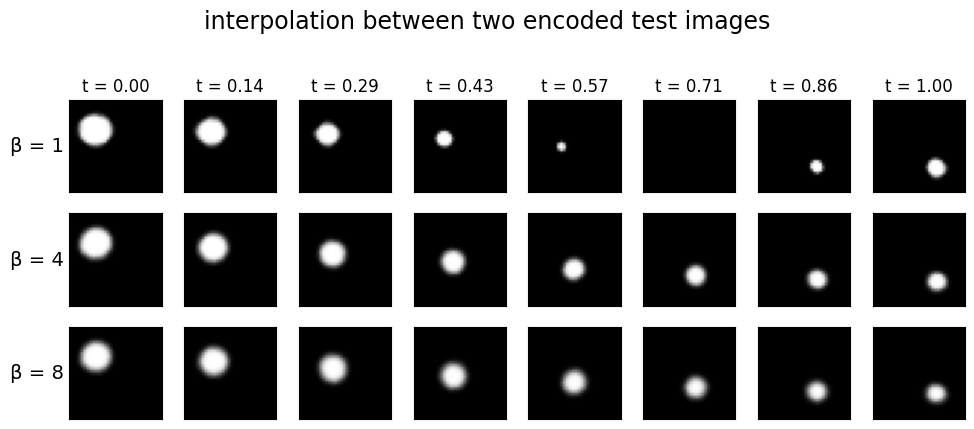

endpoints (shape, scale, orientation, x, y): [ 0  5 36  2  5] [ 2  2 17 27 29]


In [18]:
# interpolation between two encoded test images that differ in shape, scale and position
ia = int(np.where((Cte[:, 0] == 0) & (Cte[:, 1] == 5) & (Cte[:, 3] < 8) & (Cte[:, 4] < 8))[0][0])
ib = int(np.where((Cte[:, 0] == 2) & (Cte[:, 1] == 2) & (Cte[:, 3] > 23) & (Cte[:, 4] > 23))[0][0])
T = np.linspace(0, 1, 8)
fig, axs = plt.subplots(len(BETAS), 8, figsize=(10, 4.4))
with torch.no_grad():
    for r, beta in enumerate(BETAS):
        ma, mb = models[beta].encode(Xte[[ia, ib]])[0]
        path = torch.stack([ma + t * (mb - ma) for t in T])
        imgs = torch.sigmoid(models[beta].decode(path))[:, 0]
        for c in range(8):
            a = axs[r, c]; a.imshow(imgs[c], cmap="gray", vmin=0, vmax=1); a.set_xticks([]); a.set_yticks([])
            if r == 0: a.set_title(f"t = {T[c]:.2f}", fontsize=12)
            if c == 0: a.set_ylabel(f"β = {beta}", rotation=0, ha="right", va="center", fontsize=14)
plt.suptitle("interpolation between two encoded test images", y=1.0)
plt.tight_layout(); plt.savefig(f"{OUT}/beta_vae_interpolation.png", dpi=200, bbox_inches="tight"); plt.show()
print("endpoints (shape, scale, orientation, x, y):", Cte[ia], Cte[ib])

The pixel sample in the second row is what the model of equation (13) actually generates: a binary image whose border pixels are coin tosses with the probabilities shown in the first row, hence the ragged edges. The mean images of the first row are smoother because they are averages. The same eight codes produce different images in different models, since each model has its own latent axes.

Generation shows the other side of the trade-off. The VAE's means are sharper, with a mean pixel entropy (16) of 0.0171 nats against 0.0310 for β of 4 and 0.0366 for β of 8 (for reconstructions 0.0220, 0.0308 and 0.0392), but one of its eight samples is an empty canvas and another a dot of a few pixels: its codes do not fill the prior, and some prior draws land where no training image was encoded. All samples of the β-VAEs are plausible blobs. The interpolation makes the same point. Between a large sprite in the upper left and a smaller one in the lower right, the VAE's path shrinks the sprite to a dot at $t$ of 0.57 and to an empty canvas at 0.71 before it reappears, while the β-VAEs move and shrink it continuously: along their axes position and size change independently, and the straight line between two codes stays inside the region the decoder knows.

## Handwritten digits

On dSprites the factors are known. Handwritten digits have no such list, but they have obvious candidates, and the same experiment can be repeated on them to connect with the VAE of the lecture.

The MNIST data set (Modified National Institute of Standards and Technology; LeCun et al., 1998) contains 70,000 images of handwritten digits, 60,000 for training and 10,000 for testing, derived from handwriting collected by the US National Institute of Standards and Technology. Each sample $\mathbf x_i$ is a grey-level image of $28\times28$ pixels, stored as integers from 0 (background) to 255 (full ink) and scaled to the interval from 0 to 1, so that $\mathbf x_i$ is a vector of 784 numbers. Each image carries a label, the digit from 0 to 9, which the VAE does not use. Unlike dSprites, the images were not generated from a known list of factors: the variation between two 4s comes from the writers. The files are read from `data/MNIST_raw` and downloaded once if missing.

In [19]:
RAW = os.path.join(DATA, "MNIST_raw"); os.makedirs(RAW, exist_ok=True)
LOCAL = os.path.expanduser("~/.pytorch/MNIST_data/MNIST/raw")
MIRRORS = ["https://ossci-datasets.s3.amazonaws.com/mnist/", "https://storage.googleapis.com/cvdf-datasets/mnist/"]
def mnist_file(name):
    for dd in (RAW, LOCAL):
        p = os.path.join(dd, name)
        if os.path.exists(p): return open(p, "rb").read()
        if os.path.exists(p + ".gz"): return gzip.open(p + ".gz").read()
    for m in MIRRORS:
        try:
            urllib.request.urlretrieve(m + name + ".gz", os.path.join(RAW, name + ".gz"))
            return gzip.open(os.path.join(RAW, name + ".gz")).read()
        except Exception: pass
    raise RuntimeError("MNIST could not be found or downloaded")
def idx_file(name):
    b = mnist_file(name)
    if b[3] == 3:
        n, r, c = np.frombuffer(b[4:16], ">i4"); return np.frombuffer(b[16:], np.uint8).reshape(n, r * c)
    return np.frombuffer(b[8:], np.uint8)
Mtr = torch.tensor(idx_file("train-images-idx3-ubyte").astype(np.float32) / 255)
Mte = torch.tensor(idx_file("t10k-images-idx3-ubyte").astype(np.float32) / 255)
yte_m = idx_file("t10k-labels-idx1-ubyte")
print("MNIST training images:", tuple(Mtr.shape), "  test images:", tuple(Mte.shape))
ytr_m = idx_file("train-labels-idx1-ubyte")
print("training images per digit:", np.bincount(ytr_m))

MNIST training images: (60000, 784)   test images: (10000, 784)
training images per digit: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


test image 4, label 4; grey levels of rows 8-19, columns 6-21 (x 10, rounded):
[[ 0  0  0  3 10  5  0  0  0  0  0  0  0  4 10  1]
 [ 0  0  2  9  9  0  0  0  0  0  0  0  0  8 10  1]
 [ 0  0  7 10  2  0  0  0  0  0  0  0  1 10 10  1]
 [ 0  3  9  8  0  0  0  0  0  0  0  0  6 10  7  0]
 [ 0  7 10  4  0  0  0  0  0  0  0  1  9 10  3  0]
 [ 1  9 10  0  0  0  0  0  0  0  0  5 10  8  0  0]
 [ 1 10  6  0  0  0  0  0  0  0  0  7 10  7  0  0]
 [ 0  8  8  1  0  0  0  0  0  0  1 10 10  4  0  0]
 [ 0  7 10  8  3  3  3  3  5  6  8 10 10  4  0  0]
 [ 0  2  7 10 10 10 10 10  9  9 10 10 10  0  0  0]
 [ 0  0  0  2  3  3  3  3  0  0  6 10 10  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  5 10 10  2  0  0]]


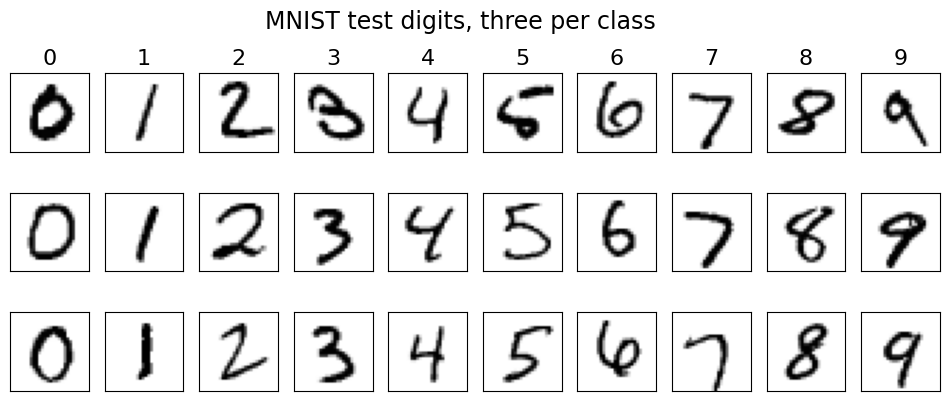

In [20]:
i0 = int(np.where(yte_m == 4)[0][0])
print(f"test image {i0}, label {yte_m[i0]}; grey levels of rows 8-19, columns 6-21 (x 10, rounded):")
print((Mte[i0].reshape(28, 28)[8:20, 6:22].numpy() * 10).round().astype(int))
fig, axs = plt.subplots(3, 10, figsize=(12, 4.4))
for r in range(3):
    for k in range(10):
        a = axs[r, k]; a.imshow(Mte[np.where(yte_m == k)[0][r]].reshape(28, 28), cmap="gray_r", vmin=0, vmax=1)
        a.set_xticks([]); a.set_yticks([])
        if r == 0: a.set_title(str(k))
plt.suptitle("MNIST test digits, three per class", y=1.0); plt.show()

The model is the dense VAE of the lecture (784–512–256 units, ten latent coordinates), trained for 10 epochs with β of 1 and of 4. Candidate factors can be measured directly on each image from its ink distribution: pixel $j$ at column $u_j$ and row $w_j$ carries ink $x_j$. The total ink is a proxy for stroke thickness,
$$m=\sum_j x_j , \tag{17}$$
the width is the standard deviation of the column under the ink distribution,
$$\mathrm{width}=\Big(\frac1m\sum_j x_j\,(u_j-\bar u)^2\Big)^{1/2},\qquad \bar u=\frac1m\sum_j x_j\,u_j , \tag{18}$$
and the slant is the regression coefficient of column on row, the horizontal shift of the stroke per row,
$$\mathrm{slant}=\frac{\mathrm{cov}(u,w)}{\mathrm{var}(w)} , \tag{19}$$
with covariance and variance taken under the same ink distribution. Rows are counted downwards, so an upright digit has zero slant and a digit leaning to the right a negative one.

In [21]:
class DenseVAE(nn.Module):
    # dense VAE of the lecture: 784 -> 512 -> 256 -> (mu, log sigma^2) in d dimensions, and back
    def __init__(self, D=784, d=10, hidden=(512, 256)):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(D, hidden[0]), nn.ReLU(), nn.Linear(hidden[0], hidden[1]), nn.ReLU(), nn.Linear(hidden[1], 2 * d))
        self.dec = nn.Sequential(nn.Linear(d, hidden[1]), nn.ReLU(), nn.Linear(hidden[1], hidden[0]), nn.ReLU(), nn.Linear(hidden[0], D))
    def encode(self, x): return self.enc(x).chunk(2, dim=1)
    def decode(self, z): return self.dec(z)
    def forward(self, x):
        mu, logvar = self.encode(x); z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
        return self.decode(z), mu, logvar

dense_info = summary(DenseVAE(), input_size=(1, 784), col_names=("output_size", "num_params"), depth=2, verbose=0)
print(dense_info)
assert dense_info.total_params == sum(p.numel() for p in DenseVAE().parameters()) == 1_074_980
nums["dense_vae_parameters"] = int(dense_info.total_params)

def train_mnist(beta, epochs=10, bs=128, lr=1e-3, seed_=1):
    seed(seed_); model = DenseVAE(); opt = torch.optim.Adam(model.parameters(), lr)
    for ep in range(epochs):
        perm = torch.randperm(len(Mtr)); tot = np.zeros(2)
        for i in range(0, len(perm), bs):
            x = Mtr[perm[i:i + bs]]
            logits, mu, logvar = model(x)
            loss, rec, kl_k = beta_vae_loss(logits, x, mu, logvar, beta)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += np.array([rec.item(), kl_k.sum().item()]) * len(x)
        if ep % 5 == 4: print(f"  beta = {beta}, epoch {ep + 1}: reconstruction {tot[0] / len(Mtr):.1f}, KL {tot[1] / len(Mtr):.1f} nats")
    return model.eval()

mnist = {}
for beta in [1, 4]:
    w = f"{RES}/beta_vae_mnist_beta{beta}.pt"
    if os.path.exists(w):
        m = DenseVAE(); m.load_state_dict(torch.load(w)); mnist[beta] = m.eval(); print(f"beta = {beta}: weights loaded")
    else:
        t0 = time.time(); mnist[beta] = train_mnist(beta); torch.save(mnist[beta].state_dict(), w)
        print(f"beta = {beta}: trained in {time.time() - t0:.0f} s")

Layer (type:depth-idx)                   Output Shape              Param #
DenseVAE                                 [1, 784]                  --
├─Sequential: 1-1                        [1, 20]                   --
│    └─Linear: 2-1                       [1, 512]                  401,920
│    └─ReLU: 2-2                         [1, 512]                  --
│    └─Linear: 2-3                       [1, 256]                  131,328
│    └─ReLU: 2-4                         [1, 256]                  --
│    └─Linear: 2-5                       [1, 20]                   5,140
├─Sequential: 1-2                        [1, 784]                  --
│    └─Linear: 2-6                       [1, 256]                  2,816
│    └─ReLU: 2-7                         [1, 256]                  --
│    └─Linear: 2-8                       [1, 512]                  131,584
│    └─ReLU: 2-9                         [1, 512]                  --
│    └─Linear: 2-10                      [1, 784]               

In [22]:
# measured properties of every test digit: total ink, width, slant
u, w = np.meshgrid(np.arange(28), np.arange(28))                 # column and row of each pixel
u, w = u.ravel().astype(np.float32), w.ravel().astype(np.float32)
P = Mte.numpy(); m0 = P.sum(1)
mu_u, mu_w = P @ u / m0, P @ w / m0
var_u = P @ u ** 2 / m0 - mu_u ** 2; var_w = P @ w ** 2 / m0 - mu_w ** 2; cov_uw = P @ (u * w) / m0 - mu_u * mu_w
props = {"ink": m0, "width": np.sqrt(var_u), "slant": cov_uw / var_w}
PROPS = list(props)

menc = {}
with torch.no_grad():
    for beta in [1, 4]:
        mu, logvar = mnist[beta].encode(Mte)
        kl = (0.5 * (mu ** 2 + logvar.exp() - logvar - 1)).mean(0).numpy()
        rec = F.binary_cross_entropy_with_logits(mnist[beta].decode(mu), Mte, reduction="sum").item() / len(Mte)
        mu = mu.numpy()
        corr = np.array([[np.corrcoef(mu[:, k], props[p])[0, 1] for p in PROPS] for k in range(10)])
        menc[beta] = dict(mu=mu, kl=kl, order=np.argsort(-kl), rec=rec, corr=corr)
        nums[f"mnist_beta{beta}_kl_per_dim_sorted"] = [round(float(v), 2) for v in np.sort(kl)[::-1]]
        nums[f"mnist_beta{beta}_n_active"] = int((kl > ACTIVE).sum())
        nums[f"mnist_beta{beta}_test_reconstruction"] = round(rec, 1)
        nums[f"mnist_beta{beta}_best_corr"] = {p: round(float(np.abs(corr[:, i]).max()), 2) for i, p in enumerate(PROPS)}
        print(f"beta = {beta}: reconstruction {rec:.1f} nats, KL sorted {np.round(np.sort(kl)[::-1], 2)}, active {int((kl > ACTIVE).sum())}")
        for i, p in enumerate(PROPS):
            o = np.argsort(-np.abs(corr[:, i]))
            print(f"   {p:6s}: best coordinate z_{o[0] + 1} (r = {corr[o[0], i]:+.2f}), second z_{o[1] + 1} (r = {corr[o[1], i]:+.2f})")

beta = 1: reconstruction 83.4 nats, KL sorted [2.54 2.25 2.12 2.06 1.96 1.91 1.89 1.59 1.41 0.  ], active 9
   ink   : best coordinate z_7 (r = -0.70), second z_6 (r = -0.39)
   width : best coordinate z_7 (r = -0.82), second z_2 (r = -0.27)
   slant : best coordinate z_10 (r = +0.69), second z_1 (r = +0.51)
beta = 4: reconstruction 102.7 nats, KL sorted [1.79 1.58 1.55 1.26 1.15 0.91 0.   0.   0.   0.  ], active 6
   ink   : best coordinate z_7 (r = -0.68), second z_5 (r = -0.52)
   width : best coordinate z_7 (r = -0.76), second z_4 (r = -0.47)
   slant : best coordinate z_3 (r = +0.75), second z_6 (r = +0.52)


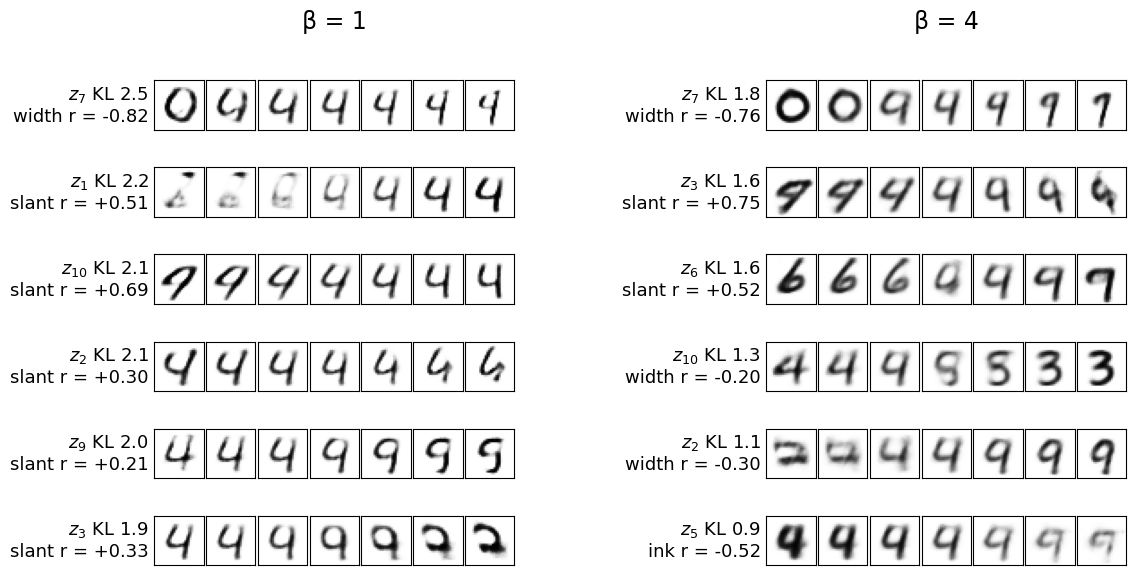

beta = 1: mean pixel entropy of 1000 generated digits 0.1226 nats
beta = 4: mean pixel entropy of 1000 generated digits 0.1554 nats


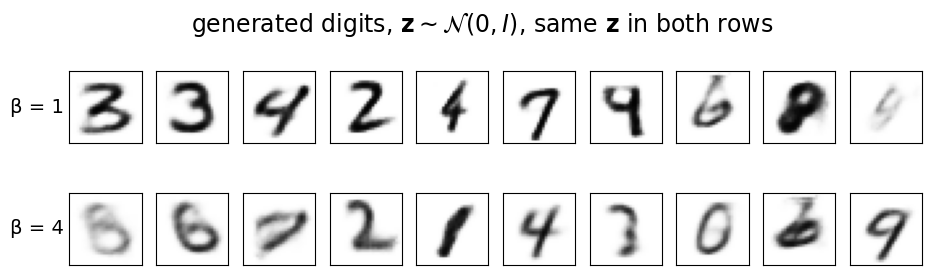

In [23]:
ZM = np.linspace(-3, 3, 7)
i_digit = i0                           # one test digit used as the seed of all traversals

def mnist_traversal_panel(fig, gs, beta, n_rows=6):
    e = menc[beta]
    with torch.no_grad():
        mu, _ = mnist[beta].encode(Mte[i_digit:i_digit + 1])
        for r, k in enumerate(e["order"][:n_rows]):
            z = mu.repeat(len(ZM), 1); z[:, k] = torch.tensor(ZM, dtype=torch.float32)
            imgs = torch.sigmoid(mnist[beta].decode(z)).reshape(-1, 28, 28).numpy()
            j = int(np.argmax(np.abs(e["corr"][k]))); rr = e["corr"][k, j]
            for c in range(len(ZM)):
                ax = fig.add_subplot(gs[r, c]); ax.imshow(imgs[c], cmap="gray_r", vmin=0, vmax=1); ax.set_xticks([]); ax.set_yticks([])
                if c == 0:
                    ax.set_ylabel(f"$z_{{{k + 1}}}$ KL {e['kl'][k]:.1f}\n{PROPS[j]} r = {rr:+.2f}", rotation=0, ha="right", va="center", fontsize=13)

fig = plt.figure(figsize=(12, 6))
mnist_traversal_panel(fig, GridSpec(6, 7, left=0.17, right=0.47, top=0.88, bottom=0.02, wspace=0.05, hspace=0.08), 1)
mnist_traversal_panel(fig, GridSpec(6, 7, left=0.68, right=0.98, top=0.88, bottom=0.02, wspace=0.05, hspace=0.08), 4)
fig.text(0.32, 0.94, "β = 1", ha="center", fontsize=17)
fig.text(0.83, 0.94, "β = 4", ha="center", fontsize=17)
plt.savefig(f"{OUT}/beta_vae_mnist_traversals.png", dpi=200, bbox_inches="tight"); plt.show()

# generation from the prior: the same z for both models
torch.manual_seed(9); Zm = torch.randn(10, 10)
fig, axs = plt.subplots(2, 10, figsize=(11, 2.9))
with torch.no_grad():
    for r, beta in enumerate([1, 4]):
        imgs = torch.sigmoid(mnist[beta].decode(Zm))
        h = pixel_entropy(torch.sigmoid(mnist[beta].decode(torch.randn(1000, 10, generator=torch.Generator().manual_seed(10)))))
        nums[f"mnist_beta{beta}_pixel_entropy_generated"] = round(h, 4)
        print(f"beta = {beta}: mean pixel entropy of 1000 generated digits {h:.4f} nats")
        for c in range(10):
            a = axs[r, c]; a.imshow(imgs[c].reshape(28, 28), cmap="gray_r", vmin=0, vmax=1); a.set_xticks([]); a.set_yticks([])
            if c == 0: a.set_ylabel(f"β = {beta}", rotation=0, ha="right", va="center", fontsize=14)
plt.suptitle(r"generated digits, $\mathbf{z}\sim\mathcal{N}(0,I)$, same $\mathbf{z}$ in both rows", y=1.04)
plt.savefig(f"{OUT}/beta_vae_mnist_samples.png", dpi=200, bbox_inches="tight"); plt.show()

On digits the VAE keeps nine active coordinates (KL between 1.41 and 2.54 nats) with a reconstruction term of 83.4 nats per test image; the β-VAE with β of 4 keeps six (between 0.91 and 1.79 nats) and reconstructs at 102.7 nats. Each measured property has a single best coordinate in both models: width correlates with one coordinate at $r$ of −0.82 for β of 1 and −0.76 for β of 4, slant at 0.69 and 0.75, total ink at −0.70 and −0.68. The second-best coordinates are not small, however (0.51 and 0.52 for slant), and the traversals show why. The leading coordinate of both models turns a wide 0 into a narrow 1 or 7, width and digit class together, and the slant coordinate of the β-VAE turns a strongly right-leaning 9 into an upright one but ends in a different digit. On MNIST the largest factor of variation is the class, which is discrete and not independent of style, and ten Gaussian coordinates cannot separate it cleanly from slant and width; β of 4 makes the slant coordinate somewhat purer but does not produce one coordinate per property.

Generation shows the same trade-off as on dSprites: the digits generated by the β-VAE are blurrier, with a mean pixel entropy of 0.155 nats against 0.123 for the VAE over 1,000 prior draws, and several of them are ambiguous between two classes.

## Summary

Raising β from 1 to 4 on dSprites cut the transmitted information from 10.2 to 6.0 nats, reduced the number of active coordinates from four to three, and doubled the mutual information gap from 0.15 to 0.30: position $x$, position $y$ and scale each moved into a coordinate of its own, visible directly in the traversals. The cost was 6.2 nats of reconstruction per image, blurrier images and the loss of the only coordinate that carried shape. The linear probes show that the VAE contains the positions almost as completely as the β-VAE; what β changes is the orientation of the axes. Samples and interpolations of the β-VAE stay plausible across the whole prior, while those of the VAE occasionally fall into empty regions of its latent space.

These are results of short runs: 8,000 steps of training at $32\times32$, one seed per model, and mutual information estimated from binned means. Orientation, which Higgins et al. found in two coordinates of a β-VAE with β of 4 at $64\times64$, and shape, which appears as a separate coordinate in the longer training of Burgess et al., did not emerge in these runs, and the numbers should be read as an illustration of the mechanism rather than as benchmark values. On handwritten digits, where the factors are not independent and the class dominates, a higher β made the slant coordinate somewhat purer but did not separate style from class.

In [24]:
nums["dsprites_subset"] = {"train": N_TRAIN, "test": N_TEST, "side": 32}
nums["training"] = {"steps": STEPS, "batch": BS, "lr": LR, "d": d}
nums["run_time_s"] = round(time.time() - T0)
json.dump(nums, open(f"{RES}/numbers_beta_vae.json", "w"), indent=1)
print(json.dumps(nums, indent=1, ensure_ascii=False))

{
 "conv_vae_parameters": 633045,
 "beta1_kl_per_dim_sorted": [
  3.305,
  3.233,
  2.523,
  1.091,
  0.001,
  0.001,
  0.0,
  0.0,
  0.0,
  0.0
 ],
 "beta1_kl_total": 10.15,
 "beta1_n_active": 4,
 "beta4_kl_per_dim_sorted": [
  2.405,
  2.375,
  1.196,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0
 ],
 "beta4_kl_total": 5.98,
 "beta4_n_active": 3,
 "beta8_kl_per_dim_sorted": [
  1.87,
  1.834,
  0.75,
  0.001,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0
 ],
 "beta8_kl_total": 4.46,
 "beta8_n_active": 3,
 "beta1_mig": 0.15,
 "beta1_nmi_rows_by_kl": {
  "z10": [
   0.02,
   0.05,
   0.01,
   0.04,
   0.21
  ],
  "z6": [
   0.01,
   0.04,
   0.01,
   0.19,
   0.05
  ],
  "z1": [
   0.05,
   0.13,
   0.01,
   0.07,
   0.05
  ],
  "z4": [
   0.37,
   0.03,
   0.13,
   0.01,
   0.01
  ],
  "z2": [
   0.02,
   0.03,
   0.01,
   0.02,
   0.02
  ],
  "z5": [
   0.03,
   0.02,
   0.01,
   0.04,
   0.08
  ],
  "z3": [
   0.01,
   0.02,
   0.01,
   0.04,
   0.05
  ],
  "z9": [
   0.03,
   0.06,
  

## References

- I. Higgins, L. Matthey, A. Pal, C. Burgess, X. Glorot, M. Botvinick, S. Mohamed, A. Lerchner, *β-VAE: Learning basic visual concepts with a constrained variational framework*, International Conference on Learning Representations (ICLR) 2017, [openreview.net/forum?id=Sy2fzU9gl](https://openreview.net/forum?id=Sy2fzU9gl).
- C. P. Burgess, I. Higgins, A. Pal, L. Matthey, N. Watters, G. Desjardins, A. Lerchner, *Understanding disentangling in β-VAE*, NIPS 2017 Workshop on Learning Disentangled Representations, [arXiv:1804.03599](https://arxiv.org/abs/1804.03599).
- D. P. Kingma, M. Welling, *Auto-encoding variational Bayes*, ICLR 2014, [arXiv:1312.6114](https://arxiv.org/abs/1312.6114).
- R. T. Q. Chen, X. Li, R. Grosse, D. Duvenaud, *Isolating sources of disentanglement in variational autoencoders*, Advances in Neural Information Processing Systems (NeurIPS) 31, 2018, [arXiv:1802.04942](https://arxiv.org/abs/1802.04942).
- X. Chen, Y. Duan, R. Houthooft, J. Schulman, I. Sutskever, P. Abbeel, *InfoGAN: Interpretable representation learning by information maximizing generative adversarial nets*, Advances in Neural Information Processing Systems 29, 2016, [arXiv:1606.03657](https://arxiv.org/abs/1606.03657).
- L. Matthey, I. Higgins, D. Hassabis, A. Lerchner, *dSprites: Disentanglement testing Sprites dataset*, 2017, [github.com/deepmind/dsprites-dataset](https://github.com/deepmind/dsprites-dataset) (Apache 2.0 licence).